In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

# Day-Ahead Cross-Border Power Price Spread Forecasting

This notebook runs the full pipeline for forecasting and backtesting day-ahead electricity price spreads across three borders (DK1-DE_LU, DK1-DK2, DK1-SE3). It pulls hourly price, load, wind/solar and NTC data from the ENTSO-E Transparency Platform, builds the features, and evaluates the forecasting models (persistence and seasonal-naive baselines, Elastic Net, ARIMA, LightGBM point/quantile and an LSTM) with expanding-window walk-forward validation and a 168-hour embargo. The forecasts are then converted into trading signals and backtested with execution costs, position ceilings and a BRP imbalance haircut, followed by stress tests, serial-dependence diagnostics and SHAP plots.

**Setup**

Python 3.11

`pip install entsoe-py pandas numpy scikit-learn lightgbm torch yfinance matplotlib seaborn holidays shap tqdm statsmodels python-dotenv beautifulsoup4 lxml pyarrow`

An ENTSO-E API token is required. Register at https://transparency.entsoe.eu, request "Restful API access" from transparency@entsoe.eu, and set the token as an environment variable: `export ENTSOE_API_KEY="your-token"`.

# Data Pipeline and Cleaning

Pulls hourly data from 1 January 2022 to 30 September 2025 from:
  - ENTSO-E Transparency Platform (day-ahead prices, load, wind/solar forecasts, NTC)
  - yfinance (TTF gas futures and an EU ETS carbon proxy)

and merges them into one hourly DataFrame saved to disk.

In [2]:
import os
import time
import logging
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv

load_dotenv()

from entsoe import EntsoePandasClient
from entsoe.exceptions import NoMatchingDataError

# CONFIG

API_KEY = os.environ.get("ENTSOE_API_KEY", "PASTE_YOUR_TOKEN_HERE")

ZONES = {
    "DK1": "DK_1",
    "DE_LU": "DE_LU",
    "DK2": "DK_2",
    "SE3": "SE_3",
}


BORDERS = [
    ("DK1", "DE_LU"),
    ("DK1", "DK2"),
    ("DK1", "SE3"),
]


START = pd.Timestamp("2022-01-01", tz="Europe/Copenhagen")
END = pd.Timestamp("2025-09-30", tz="Europe/Copenhagen")

# ENTSO-E limits the query range to one month for load, wind/solar and NTC,
# so these are fetched in chunks of at most CHUNK_MAX_DAYS.
CHUNK_MAX_DAYS = 27

OUTPUT_DIR = Path("./data")
OUTPUT_DIR.mkdir(exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)

client = EntsoePandasClient(api_key=API_KEY)


# HELPERS

def _safe_call(fn, *args, label="", retries=3, pause=5, **kwargs):
    """Wrap an entsoe-py call with retries, since the API can be flaky and occasionally rate-limits or times out on large date ranges."""
    for attempt in range(1, retries + 1):
        try:
            return fn(*args, **kwargs)
        except NoMatchingDataError:
            log.warning(f"No data returned for {label} ({args}, {kwargs}) — treating as missing")
            return None
        except Exception as e:
            log.warning(f"[{label}] attempt {attempt}/{retries} failed: {e}")
            if attempt == retries:
                raise
            time.sleep(pause)


def _month_chunks(start: pd.Timestamp, end: pd.Timestamp, max_days: int = CHUNK_MAX_DAYS):
    """Split [start, end) into contiguous sub-ranges of at most max_days."""
    chunk_start = start
    while chunk_start < end:
        chunk_end = min(chunk_start + pd.Timedelta(days=max_days), end)
        yield chunk_start, chunk_end
        chunk_start = chunk_end


def _chunked_call(fn, *args, label="", max_days: int = CHUNK_MAX_DAYS, **kwargs):
    """Like _safe_call, but fetches the START..END range in chunks of at most max_days and concatenates them, since ENTSO-E limits the query range for some document types."""
    parts = []
    any_data = False
    for chunk_start, chunk_end in _month_chunks(START, END, max_days=max_days):
        result = _safe_call(
            fn, *args, start=chunk_start, end=chunk_end,
            label=f"{label}_{chunk_start.date()}", **kwargs,
        )
        if result is not None:
            parts.append(result)
            any_data = True
    if not any_data:
        return None
    combined = pd.concat(parts)
    # Adjacent chunks share their boundary instant (chunk N's end ==
    # chunk N+1's start); if ENTSO-E returns that instant in both
    # responses, drop the duplicate rather than double-counting it.
    combined = combined[~combined.index.duplicated(keep="first")].sort_index()
    return combined


def fetch_day_ahead_prices(zone: str) -> pd.Series | None:
    log.info(f"Fetching day-ahead prices for {zone}")
    s = _safe_call(client.query_day_ahead_prices, zone, start=START, end=END, label=f"day_ahead_prices_{zone}")
    if s is None:
        return None
    s.name = f"price_{zone}"
    return s


def fetch_load(zone: str) -> pd.DataFrame | None:
    log.info(f"Fetching load forecast & actual for {zone}")
    df = _chunked_call(client.query_load_and_forecast, zone, label=f"load_{zone}")
    if df is None:
        return None
    df = df.rename(columns={
        "Forecasted Load": f"load_forecast_{zone}",
        "Actual Load": f"load_actual_{zone}",
    })
    return df


def fetch_wind_solar_forecast(zone: str) -> pd.DataFrame | None:
    log.info(f"Fetching wind & solar forecast for {zone}")
    df = _chunked_call(
        client.query_wind_and_solar_forecast, zone,
        psr_type=None, label=f"wind_solar_{zone}",
    )
    if df is None:
        return None


    df = df.add_suffix(f"_{zone}")
    return df


def fetch_ntc(zone_from: str, zone_to: str) -> pd.Series | None:
    """Net Transfer Capacity in one direction."""
    log.info(f"Fetching NTC {zone_from} -> {zone_to}")
    s = _chunked_call(
        client.query_net_transfer_capacity_dayahead,
        zone_from, zone_to,
        label=f"ntc_{zone_from}_{zone_to}",
    )
    if s is None:
        log.warning(
            f"NTC {zone_from}->{zone_to}: no data across the whole date range. "
            "This border's NTC feature will be all-NaN. If unexpected, verify "
            "on the ENTSO-E Transparency Platform whether NTC is published for "
            "this pair, or try query_crossborder_flows as a substitute."
        )
        return None
    if isinstance(s, pd.DataFrame):
        s = s.iloc[:, 0]
    s.name = f"ntc_{zone_from}_to_{zone_to}"
    return s


def fetch_commodity_proxies() -> pd.DataFrame:
    """Daily TTF gas futures + EU ETS carbon proxy via yfinance."""
    import yfinance as yf

    log.info("Fetching commodity proxies (TTF gas, carbon)")
    tickers = {
        "ttf_gas_proxy": "TTF=F",
        "eu_carbon_proxy": "KRBN",
    }

    frames = []
    for name, ticker in tickers.items():
        try:
            hist = yf.download(ticker, start=START.date(), end=END.date(), progress=False)
            if hist.empty:
                log.warning(f"No yfinance data for {ticker} ({name}) — skipping")
                continue


            close = hist["Close"]
            if isinstance(close, pd.DataFrame):
                close = close.squeeze("columns")
            close.name = name
            frames.append(close)
        except Exception as e:
            log.warning(f"Failed to fetch {ticker} ({name}): {e}")
            log.warning("Full traceback:", exc_info=True)

    if not frames:
        return pd.DataFrame()

    df = pd.concat(frames, axis=1)
    idx = pd.to_datetime(df.index)
    if getattr(idx, "tz", None) is None:
        idx = idx.tz_localize("UTC")
    else:
        idx = idx.tz_convert("UTC")
    df.index = idx.tz_convert("Europe/Copenhagen")


    df = df.sort_index().shift(1)
    return df


# MAIN PIPELINE

def build_dataset() -> pd.DataFrame:


    mtu_transition = pd.Timestamp("2025-10-01", tz="Europe/Copenhagen")
    if END >= mtu_transition:
        raise ValueError(
            f"END ({END.date()}) is on or after the SDAC 15-minute MTU transition "
            f"(2025-10-01). Day-ahead data from this date onward is 15-minute "
            "resolution, not hourly, and will not merge cleanly with earlier data. "
            "Either set END before 2025-10-01, or explicitly handle the granularity "
            "change (e.g. resample post-transition data to hourly means) before "
            "removing this check."
        )


    needed_zone_names = sorted({z for pair in BORDERS for z in pair})
    log.info(f"Zones required by BORDERS: {needed_zone_names}")


    price_series = {}
    for zone_name in needed_zone_names:
        code = ZONES[zone_name]
        s = fetch_day_ahead_prices(code)
        if s is None:


            raise RuntimeError(
                f"No day-ahead price data returned for {zone_name} ({code}) across "
                f"{START.date()}..{END.date()}. This zone is required by BORDERS "
                "and the pipeline can't proceed without its price series."
            )
        price_series[zone_name] = s

    prices = pd.concat(price_series.values(), axis=1)


    for zone_a, zone_b in BORDERS:
        code_a, code_b = ZONES[zone_a], ZONES[zone_b]
        prices[f"spread_{zone_a}_{zone_b}"] = prices[f"price_{code_a}"] - prices[f"price_{code_b}"]


    load_frames = [fetch_load(ZONES[z]) for z in needed_zone_names]
    ws_frames = [fetch_wind_solar_forecast(ZONES[z]) for z in needed_zone_names]


    ntc_frames = []
    missing_ntc_cols = []
    for zone_a, zone_b in BORDERS:
        code_a, code_b = ZONES[zone_a], ZONES[zone_b]
        for c_from, c_to in [(code_a, code_b), (code_b, code_a)]:
            s = fetch_ntc(c_from, c_to)
            if s is None:
                missing_ntc_cols.append(f"ntc_{c_from}_to_{c_to}")
            else:
                ntc_frames.append(s)


    commodities = fetch_commodity_proxies()


    frames_to_join = [f for f in (load_frames + ws_frames + ntc_frames) if f is not None]
    n_dropped = len(load_frames) + len(ws_frames) + len(ntc_frames) - len(frames_to_join)
    if n_dropped:
        log.warning(f"{n_dropped} fetch result(s) were empty/missing and excluded from the join "
                    "(see warnings above for which). Their columns will be added back as all-NaN "
                    "after resample so Phase 3 doesn't KeyError on a missing column.")

    log.info("Merging all sources on hourly index")
    df = prices.join(frames_to_join, how="outer")


    if not isinstance(df.index, pd.DatetimeIndex):
        raise TypeError(
            f"Merged index is {type(df.index).__name__}, not DatetimeIndex, after "
            "joining prices with load/wind-solar/NTC frames. This means one of the "
            "join inputs had an incompatible index despite the None-filtering above -- "
            "check for a fetch function returning something other than None on failure."
        )


    df = df.resample("h").mean()


    for col in missing_ntc_cols:
        df[col] = np.nan
        log.warning(f"Added '{col}' as an all-NaN column (no data available for this NTC direction)")


    if not commodities.empty:
        commodities_hourly = commodities.reindex(df.index, method="ffill")
        df = df.join(commodities_hourly)

    return df


def clean_dataset(df: pd.DataFrame) -> pd.DataFrame:
    log.info("Cleaning dataset")

    before = len(df)

    target_cols = [f"spread_{a}_{b}" for a, b in BORDERS]


    df = df.dropna(subset=target_cols)


    predictor_cols = [c for c in df.columns if c not in target_cols]
    actual_load_cols = [c for c in predictor_cols if c.startswith("load_actual_")]
    if actual_load_cols:
        log.info(
            f"Actual load retained for audit only; excluded from modelling in Phase 3: "
            f"{actual_load_cols}"
        )

    missing_report = df[predictor_cols].isna().mean().sort_values(ascending=False)
    missing_report = missing_report[missing_report > 0]
    if len(missing_report):
        log.info(
            f"Predictor missing-value share passed to Phase 3 (no imputation in Phase 2):\n"
            f"{missing_report}"
        )

    log.info(f"Rows before cleaning: {before}, after: {len(df)}")
    return df


if __name__ == "__main__":
    if API_KEY == "PASTE_YOUR_TOKEN_HERE":
        raise SystemExit(
            "Set your ENTSO-E API key first: export ENTSOE_API_KEY='your-token' "
            "or edit API_KEY at the top of this script."
        )

    raw_df = build_dataset()
    clean_df = clean_dataset(raw_df)

    raw_path = OUTPUT_DIR / "raw_hourly_dataset.parquet"
    clean_path = OUTPUT_DIR / "clean_hourly_dataset.parquet"

    raw_df.to_parquet(raw_path)
    clean_df.to_parquet(clean_path)

    log.info(f"Saved raw dataset -> {raw_path} ({raw_df.shape})")
    log.info(f"Saved clean dataset -> {clean_path} ({clean_df.shape})")
    print(clean_df.tail())

2026-09-04 19:59:54,114 | INFO | Zones required by BORDERS: ['DE_LU', 'DK1', 'DK2', 'SE3']
2026-09-04 19:59:54,114 | INFO | Fetching day-ahead prices for DE_LU
2026-09-04 20:00:55,419 | WARNING | [day_ahead_prices_DE_LU] attempt 1/3 failed: 503 Server Error: Service Unavailable for url: https://web-api.tp.entsoe.eu/api?documentType=A44&in_Domain=10Y1001A1001A82H&out_Domain=10Y1001A1001A82H&offset=300&contract_MarketAgreement.type=A01&classificationSequence_AttributeInstanceComponent.position=1&securityToken=REDACTED&periodStart=202212302300&periodEnd=202312302300
2026-09-04 20:03:55,730 | INFO | Fetching day-ahead prices for DK_1
2026-09-04 20:05:55,625 | INFO | Fetching day-ahead prices for DK_2
2026-09-04 20:07:55,126 | INFO | Fetching day-ahead prices for SE_3
2026-09-04 20:10:19,938 | INFO | Fetching load forecast & actual for DE_LU
2026-09-04 20:20:53,471 | INFO | Fetching load forecast & actual for DK_1
2026-09-04 20:30:55,101 | INFO | Fetching load forecast & actual for DK_2
202

                           price_DE_LU  price_DK_1  price_DK_2  price_SE_3  \
2025-09-29 18:00:00+00:00       167.60      167.60      167.47      107.41   
2025-09-29 19:00:00+00:00       123.85      123.85      123.79       86.65   
2025-09-29 20:00:00+00:00       108.30      108.30      108.10       44.22   
2025-09-29 21:00:00+00:00        93.68       93.68       93.46       27.00   
2025-09-29 22:00:00+00:00       101.10       97.43      100.85       25.25   

                           spread_DK1_DE_LU  spread_DK1_DK2  spread_DK1_SE3  \
2025-09-29 18:00:00+00:00              0.00            0.13           60.19   
2025-09-29 19:00:00+00:00              0.00            0.06           37.20   
2025-09-29 20:00:00+00:00              0.00            0.20           64.08   
2025-09-29 21:00:00+00:00              0.00            0.22           66.68   
2025-09-29 22:00:00+00:00             -3.67           -3.42           72.18   

                           load_forecast_DE_LU  load_act

# Feature Engineering

Reads `./data/clean_hourly_dataset.parquet` and builds the feature set for every border:

  - Lagged spreads (t-24, t-48, t-168)
  - Wind forecast differential
  - Residual demand per zone
  - Calendar indicators (hour, day of week, month, holiday dummies per zone)

Output: `./data/model_ready_dataset.parquet`, one row per hour with the targets and features for all borders.

In [3]:
import logging
from pathlib import Path

import numpy as np
import pandas as pd

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)

DATA_DIR = Path("./data")
INPUT_PATH = DATA_DIR / "clean_hourly_dataset.parquet"
OUTPUT_PATH = DATA_DIR / "model_ready_dataset.parquet"


ZONES = {
    "DK1": "DK_1",
    "DE_LU": "DE_LU",
    "DK2": "DK_2",
    "SE3": "SE_3",
}
BORDERS = [
    ("DK1", "DE_LU"),
    ("DK1", "DK2"),
    ("DK1", "SE3"),
]


ZONE_COUNTRY = {
    "DK1": "DK",
    "DK2": "DK",
    "DE_LU": "DE",
    "SE3": "SE",
}

TARGET_COLS = [f"spread_{a}_{b}" for a, b in BORDERS]

try:
    import holidays as pyholidays
    HAS_HOLIDAYS_LIB = True
except ImportError:
    HAS_HOLIDAYS_LIB = False
    log.warning(
    )


# HELPERS

def find_col(df: pd.DataFrame, prefix: str, zone_code: str) -> str | None:
    """Find a column by name pattern; the available series differ by zone."""
    candidates = [c for c in df.columns if c.startswith(prefix) and c.endswith(f"_{zone_code}")]
    if not candidates:
        log.warning(f"No column found for prefix='{prefix}', zone='{zone_code}'")
        return None
    if len(candidates) > 1:
        log.warning(f"Multiple matches for prefix='{prefix}', zone='{zone_code}': {candidates} — using first")
    return candidates[0]


def total_wind(df: pd.DataFrame, zone_code: str) -> pd.Series:
    """Sum onshore + offshore wind if both exist; fall back to whichever is present."""
    onshore_col = find_col(df, "Wind Onshore", zone_code)
    offshore_col = find_col(df, "Wind Offshore", zone_code)

    parts = []
    if onshore_col:
        parts.append(df[onshore_col])
    if offshore_col:
        parts.append(df[offshore_col])

    if not parts:
        log.warning(f"No wind columns found for zone {zone_code} — returning all-NaN series")
        return pd.Series(np.nan, index=df.index)


    total = pd.concat(parts, axis=1).sum(axis=1, min_count=len(parts))
    return total


def solar(df: pd.DataFrame, zone_code: str) -> pd.Series:
    solar_col = find_col(df, "Solar", zone_code)
    if solar_col is None:
        return pd.Series(0.0, index=df.index)
    return df[solar_col]


def load_forecast(df: pd.DataFrame, zone_code: str) -> pd.Series:
    col = f"load_forecast_{zone_code}"
    if col not in df.columns:
        raise KeyError(f"Expected column '{col}' not found — check Phase 2 output")
    return df[col]


# FEATURE BLOCKS

def add_lagged_spreads(df: pd.DataFrame) -> pd.DataFrame:
    log.info("Adding lagged spread features for every border")
    for target in TARGET_COLS:
        df[f"{target}_lag_24"] = df[target].shift(24)
        df[f"{target}_lag_48"] = df[target].shift(48)
        df[f"{target}_lag_168"] = df[target].shift(168)
    return df


def add_wind_forecast_differential(df: pd.DataFrame) -> pd.DataFrame:
    log.info("Adding wind forecast differential per border")


    zone_names = sorted({z for pair in BORDERS for z in pair})
    wind_by_zone = {}
    for zone_name in zone_names:
        code = ZONES[zone_name]
        wind_by_zone[zone_name] = total_wind(df, code)
        df[f"wind_total_{zone_name}"] = wind_by_zone[zone_name]

    for zone_a, zone_b in BORDERS:
        df[f"delta_wind_{zone_a}_{zone_b}"] = wind_by_zone[zone_a] - wind_by_zone[zone_b]
    return df


def add_residual_demand(df: pd.DataFrame) -> pd.DataFrame:
    log.info("Adding residual demand per zone")
    zone_names = sorted({z for pair in BORDERS for z in pair})
    for zone_name in zone_names:
        code = ZONES[zone_name]
        load = load_forecast(df, code)
        wind = total_wind(df, code)
        sol = solar(df, code)
        df[f"residual_demand_{zone_name}"] = load - (wind + sol)
    return df


def add_calendar_features(df: pd.DataFrame) -> pd.DataFrame:
    log.info("Adding calendar features")
    idx = df.index

    df["hour"] = idx.hour
    df["day_of_week"] = idx.dayofweek
    df["month"] = idx.month
    df["is_weekend"] = (idx.dayofweek >= 5).astype(int)

    zone_names = sorted({z for pair in BORDERS for z in pair})
    idx_dates = idx.tz_convert("Europe/Copenhagen").date

    if HAS_HOLIDAYS_LIB:
        years = sorted(idx.year.unique().tolist())


        holiday_dummies = {}
        for zone_name in zone_names:
            country = ZONE_COUNTRY[zone_name]
            zone_holidays = pyholidays.country_holidays(country, years=years)
            zone_dates = set(zone_holidays.keys())
            col = f"is_holiday_{zone_name}"
            df[col] = pd.Series(idx_dates, index=idx).isin(zone_dates).astype(int)
            holiday_dummies[zone_name] = df[col]


        for zone_a, zone_b in BORDERS:
            df[f"is_holiday_either_{zone_a}_{zone_b}"] = (
                holiday_dummies[zone_a] | holiday_dummies[zone_b]
            ).astype(int)
    else:
        for zone_name in zone_names:
            df[f"is_holiday_{zone_name}"] = 0
        for zone_a, zone_b in BORDERS:
            df[f"is_holiday_either_{zone_a}_{zone_b}"] = 0


    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
    df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

    return df


# MAIN

def build_features() -> pd.DataFrame:
    if not INPUT_PATH.exists():
        raise FileNotFoundError(
            f"{INPUT_PATH} not found — run the Phase 2 pipeline first."
        )

    log.info(f"Loading {INPUT_PATH}")
    df = pd.read_parquet(INPUT_PATH)

    missing_targets = [t for t in TARGET_COLS if t not in df.columns]
    if missing_targets:
        raise KeyError(
            f"Expected target column(s) {missing_targets} not found in {INPUT_PATH}. "
            "Phase 2's BORDERS config must match Phase 3's — check both are in sync."
        )


    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    if df.index.tz is None:
        df.index = df.index.tz_localize("UTC")
    else:
        df.index = df.index.tz_convert("UTC")
    df = df.sort_index()

    full_hourly_index = pd.date_range(
        start=df.index.min().floor("h"),
        end=df.index.max().ceil("h"),
        freq="h",
        tz="UTC",
    )
    rows_before_reindex = len(df)
    df = df.reindex(full_hourly_index)
    inserted = len(df) - rows_before_reindex
    if inserted > 0:
        log.info(
            f"Reindexed to a strict hourly UTC grid: inserted {inserted} missing timestamp row(s) "
            "before lag construction and causal imputation"
        )


    df = add_lagged_spreads(df)
    df = add_wind_forecast_differential(df)
    df = add_residual_demand(df)
    df = add_calendar_features(df)

    return df


def _missing_gap_length_counts(df: pd.DataFrame, cols: list[str]) -> pd.Series:
    """Return counts of missing observations grouped by consecutive-gap length."""
    gap_counts: dict[int, int] = {}

    for col in cols:
        is_missing = df[col].isna().to_numpy()
        if not is_missing.any():
            continue

        starts = np.flatnonzero(is_missing & ~np.r_[False, is_missing[:-1]])
        ends = np.flatnonzero(is_missing & ~np.r_[is_missing[1:], False])
        lengths = ends - starts + 1

        for length in lengths:
            length = int(length)
            gap_counts[length] = gap_counts.get(length, 0) + length

    return pd.Series(gap_counts, dtype="int64").sort_index()


def finalize(df: pd.DataFrame) -> pd.DataFrame:
    """Finalize the strictly-hourly model-ready dataset."""
    before = len(df)


    actual_load_cols = [c for c in df.columns if c.startswith("load_actual_")]
    if actual_load_cols:
        log.info(
            f"Dropping realized load columns from model-ready dataset: {actual_load_cols}"
        )
        df = df.drop(columns=actual_load_cols)


    feature_cols_pre = [
        c for c in df.columns
        if c not in TARGET_COLS and not c.startswith("price_")
    ]


    fully_missing = [c for c in feature_cols_pre if df[c].isna().all()]
    if fully_missing:
        log.warning(
            f"Dropping {len(fully_missing)} fully-missing feature column(s): {fully_missing}"
        )
        df = df.drop(columns=fully_missing)
        feature_cols_pre = [c for c in feature_cols_pre if c not in fully_missing]

    remaining_na = df[feature_cols_pre].isna().mean().sort_values(ascending=False)
    remaining_na = remaining_na[remaining_na > 0]

    if len(remaining_na):
        log.info(
            "Applying causal forward-fill to predictor gaps (max 3 consecutive clock hours)"
        )
        log.info(
            f"Predictor columns with missing values before fill:\n{remaining_na}"
        )


        gap_counts = _missing_gap_length_counts(df, feature_cols_pre)
        if len(gap_counts):
            log.info("Missing-gap diagnostics (missing rows by consecutive clock-hour gap length):")
            for gap_len, row_count in gap_counts.items():
                log.info(
                    f"  {gap_len} hour{'s' if gap_len != 1 else ''}: {row_count} rows"
                )
        else:
            log.info("Missing-gap diagnostics: no predictor gaps found")


        df[feature_cols_pre] = df[feature_cols_pre].ffill(limit=3)

        unresolved = df[feature_cols_pre].isna().sum()
        unresolved = unresolved[unresolved > 0]
        if len(unresolved):
            unresolved_rows = df[feature_cols_pre].isna().any(axis=1)
            unresolved_count = int(unresolved_rows.sum())
            log.info(
                f"Dropping rows with unresolved predictor gaps "
                f"(leading gaps or gaps >3 hours): {unresolved.to_dict()}"
            )

            df = df.loc[~unresolved_rows].copy()
            log.info(f"Dropped {unresolved_count} rows with unresolved predictor gaps")
        else:
            log.info("No unresolved predictor gaps remain after causal forward-fill")
    else:
        log.info("No predictor gaps found before causal forward-fill")


    lag_168_cols = [f"{t}_lag_168" for t in TARGET_COLS]
    target_missing_rows = df[TARGET_COLS + lag_168_cols].isna().any(axis=1)
    target_drop_count = int(target_missing_rows.sum())
    df = df.loc[~target_missing_rows].copy()
    log.info(
        f"Dropped {target_drop_count} rows with missing targets or unavailable t-168 lags; "
        f"rows before finalize: {before}, final rows: {len(df)}"
    )


    model_feature_cols = [
        c for c in df.columns
        if c not in TARGET_COLS and not c.startswith("price_")
    ]

    assert df.isna().sum().sum() == 0, (
        "Unexpected NaNs remain after imputation/target filtering — investigate before proceeding"
    )

    log.info(
        f"Final model feature columns ({len(model_feature_cols)}): {model_feature_cols}"
    )
    return df


if __name__ == "__main__":
    feat_df = build_features()
    final_df = finalize(feat_df)

    final_df.to_parquet(OUTPUT_PATH)
    log.info(f"Saved model-ready dataset -> {OUTPUT_PATH} ({final_df.shape})")

    model_feature_cols = [
        c for c in final_df.columns
        if c not in TARGET_COLS and not c.startswith("price_")
    ]
    log.info(f"Feature columns ({len(model_feature_cols)}): {model_feature_cols}")
    print(final_df[TARGET_COLS + model_feature_cols[:8]].tail())


2026-09-04 21:38:05,902 | INFO | Loading data/clean_hourly_dataset.parquet
2026-09-04 21:38:06,055 | INFO | Reindexed to a strict hourly UTC grid: inserted 3 missing timestamp row(s) before lag construction and causal imputation
2026-09-04 21:38:06,055 | INFO | Adding lagged spread features for every border
2026-09-04 21:38:06,059 | INFO | Adding wind forecast differential per border
2026-09-04 21:38:06,074 | WARNING | No column found for prefix='Wind Offshore', zone='SE_3'
2026-09-04 21:38:06,078 | INFO | Adding residual demand per zone
2026-09-04 21:38:06,092 | WARNING | No column found for prefix='Wind Offshore', zone='SE_3'
2026-09-04 21:38:06,096 | INFO | Adding calendar features
2026-09-04 21:38:06,246 | INFO | Dropping realized load columns from model-ready dataset: ['load_actual_DE_LU', 'load_actual_DK_1', 'load_actual_DK_2', 'load_actual_SE_3']
2026-09-04 21:38:06,251 | WARNING | Dropping 4 fully-missing feature column(s): ['ntc_DK_1_to_DK_2', 'ntc_DK_2_to_DK_1', 'ntc_DK_1_to_

                           spread_DK1_DE_LU  spread_DK1_DK2  spread_DK1_SE3  \
2025-09-29 18:00:00+00:00              0.00            0.13           60.19   
2025-09-29 19:00:00+00:00              0.00            0.06           37.20   
2025-09-29 20:00:00+00:00              0.00            0.20           64.08   
2025-09-29 21:00:00+00:00              0.00            0.22           66.68   
2025-09-29 22:00:00+00:00             -3.67           -3.42           72.18   

                           load_forecast_DE_LU  load_forecast_DK_1  \
2025-09-29 18:00:00+00:00           59507.4375              2920.0   
2025-09-29 19:00:00+00:00           56297.0200              2870.0   
2025-09-29 20:00:00+00:00           52638.6125              2863.0   
2025-09-29 21:00:00+00:00           48958.2200              2837.0   
2025-09-29 22:00:00+00:00           48958.2200              2837.0   

                           load_forecast_DK_2  load_forecast_SE_3  \
2025-09-29 18:00:00+00:00          

## Information-set convention

The target is the day-ahead spread for delivery hour *t*. ENTSO-E forecast products are treated as day-ahead forecasts for the delivery hour and assumed available before the auction. The data has no publication timestamps, so this is an assumption and is tested in the lag-robustness check at the end. Realized load is excluded from the model inputs. The realized spread is only used for evaluation and, in the backtest, for risk estimation with a 24-hour lag.

Yahoo Finance observations are shifted by one market session because exact publication times are not available.

DK1 is connected to SE3 through the Konti-Skan cable (DK2 connects to SE4), so DK1-SE3 is used as the third border.

# Predictive Modeling

Expanding-window walk-forward validation with five folds and a 168-hour embargo. Inner model selection uses the same 168-hour gap. Models:
  1. Persistence (t-24)
  2. Seasonal naive (t-168)
  3. Elastic Net with interactions
  4. LightGBM point forecast
  5. LightGBM quantile forecasts (10/50/90)
  6. LSTM (sequence-to-one, 168-hour lookback)

Outputs per border: fold metrics, test predictions, Diebold-Mariano tests and the final model files.

The LSTM predicts row *p* from the 168 rows strictly before *p*. Test windows may look back into rows that were embargoed out of training, since the embargo restricts what the model is fitted on and not what it may see at prediction time. The fit/validation split used for early stopping applies the same embargo.

In [4]:
"""Predictive modeling: walk-forward evaluation of all forecasting models."""

import logging
import pickle
import time
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

try:
    from tqdm.auto import tqdm
    HAS_TQDM = True
except ImportError:
    HAS_TQDM = False

    class tqdm:
        def __init__(self, iterable=None, total=None, desc=None, **kwargs):
            self.iterable = iterable
            self.desc = desc

        def __iter__(self):
            return iter(self.iterable) if self.iterable is not None else iter([])

        def set_postfix(self, *a, **k):
            pass

        def set_description(self, desc):
            self.desc = desc

        def update(self, n=1):
            pass

        def close(self):
            pass

        def __enter__(self):
            return self

        def __exit__(self, *exc):
            self.close()

        @staticmethod
        def write(msg):
            print(msg)

try:
    import lightgbm as lgb
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

try:
    from IPython.display import display
    HAS_IPYTHON = True
except ImportError:
    HAS_IPYTHON = False

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)


@contextmanager
def _timed(label: str):
    """Print how long a block took."""
    t0 = time.time()
    tqdm.write(f"  -> starting {label}...")
    yield
    tqdm.write(f"  -> {label} done in {time.time() - t0:.1f}s")

DATA_DIR = Path("./data")
MODEL_DIR = Path("./models")
MODEL_DIR.mkdir(exist_ok=True)
INPUT_PATH = DATA_DIR / "model_ready_dataset.parquet"

ZONES = {"DK1": "DK_1", "DE_LU": "DE_LU", "DK2": "DK_2", "SE3": "SE_3"}
BORDERS = [("DK1", "DE_LU"), ("DK1", "DK2"), ("DK1", "SE3")]
TARGET_COLS = [f"spread_{a}_{b}" for a, b in BORDERS]

N_FOLDS = 5
MIN_TRAIN_FRAC = 0.4
EMBARGO_HOURS = 168
EN_CV_SPLITS = 5
QUANTILES = [0.1, 0.5, 0.9]
DIRECTIONAL_EVAL_THRESHOLD = 1.0
SEED = 42

LOOKBACK_HOURS = 168

SEQ_HIDDEN_SIZE = 32
SEQ_NUM_LAYERS = 2
SEQ_DROPOUT = 0.1
SEQ_BATCH_SIZE = 256
SEQ_MAX_EPOCHS = 25
SEQ_PATIENCE = 6

SEQ_LR = 1e-3
SEQ_VAL_FRAC = 0.15
FINAL_SEQ_MAX_EPOCHS = 25

if HAS_TORCH:
    torch.manual_seed(SEED)


# STYLED TABLE DISPLAY

def style_table(df: pd.DataFrame, caption: str = None, money_cols: list[str] = None,
                pct_cols: list[str] = None, highlight_max_cols: list[str] = None,
                highlight_min_cols: list[str] = None, decimals: int = 3):
    """Format a DataFrame for notebook display."""
    money_cols = money_cols or []
    pct_cols = pct_cols or []
    highlight_max_cols = highlight_max_cols or []
    highlight_min_cols = highlight_min_cols or []

    fmt = {}
    for c in df.columns:
        if c in money_cols:
            fmt[c] = "€{:,.0f}"
        elif c in pct_cols:
            fmt[c] = "{:.1%}"
        elif pd.api.types.is_float_dtype(df[c]):
            fmt[c] = f"{{:.{decimals}f}}"

    styler = df.style.format(fmt, na_rep="-").hide(axis="index")
    if caption:
        styler = styler.set_caption(caption)
    for c in highlight_max_cols:
        if c in df.columns:
            styler = styler.highlight_max(subset=[c], color="#c6efce")
    for c in highlight_min_cols:
        if c in df.columns:
            styler = styler.highlight_min(subset=[c], color="#ffc7ce")

    if HAS_IPYTHON:
        display(styler)
    else:
        print(f"\n{caption or ''}")
        print(df.to_string(index=False))
    return styler

# FEATURES / INTERACTIONS

def get_feature_columns(df: pd.DataFrame) -> list[str]:
    exclude = set(TARGET_COLS) | {f"price_{code}" for code in ZONES.values()}
    return [c for c in df.columns if c not in exclude]


def add_interaction_terms(df: pd.DataFrame, base_features: list[str],
                          zone_a: str, zone_b: str) -> tuple[pd.DataFrame, list[str]]:
    df = df.copy()
    new_cols = []
    code_a, code_b = ZONES[zone_a], ZONES[zone_b]
    wind_diff_col = f"delta_wind_{zone_a}_{zone_b}"
    ntc_col = f"ntc_{code_a}_to_{code_b}"
    resdem_a_col = f"residual_demand_{zone_a}"
    resdem_b_col = f"residual_demand_{zone_b}"

    if ntc_col not in df.columns:
        log.warning(f"'{ntc_col}' not in dataset — skipping NTC-based interactions for {zone_a}-{zone_b}")
    else:
        if wind_diff_col in df.columns:
            df["interact_wind_ntc"] = df[wind_diff_col] * df[ntc_col]
            new_cols.append("interact_wind_ntc")
        if resdem_a_col in df.columns and resdem_b_col in df.columns:
            df["residual_demand_diff"] = df[resdem_a_col] - df[resdem_b_col]
            df["interact_resdemand_ntc"] = df["residual_demand_diff"] * df[ntc_col]
            new_cols.extend(["residual_demand_diff", "interact_resdemand_ntc"])
    return df, base_features + new_cols

# WALK-FORWARD SPLITS

def make_walk_forward_folds(n_rows: int, n_folds: int = N_FOLDS,
                            min_train_frac: float = MIN_TRAIN_FRAC,
                            embargo_hours: int = EMBARGO_HOURS):
    min_train_size = int(n_rows * min_train_frac)
    remaining = n_rows - min_train_size
    test_size = remaining // n_folds
    folds = []
    train_end = min_train_size
    for _ in range(n_folds):
        test_start = train_end
        test_end = min(test_start + test_size, n_rows)
        if test_start >= n_rows:
            break
        embargoed_train_end = max(0, train_end - embargo_hours)
        folds.append((slice(0, embargoed_train_end), slice(test_start, test_end)))
        train_end = test_end
    return folds

# METRICS

def directional_accuracy(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean(np.sign(y_true) == np.sign(y_pred)))


def directional_accuracy_threshold(y_true: np.ndarray, y_pred: np.ndarray,
                                   threshold: float = DIRECTIONAL_EVAL_THRESHOLD) -> float:
    mask = np.abs(y_true) > threshold
    if not mask.any():
        return float("nan")
    return float(np.mean(np.sign(y_true[mask]) == np.sign(y_pred[mask])))


def evaluate(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    if not mask.all():
        y_true, y_pred = y_true[mask], y_pred[mask]
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "directional_accuracy": directional_accuracy(y_true, y_pred),
        "directional_accuracy_gt_1": directional_accuracy_threshold(y_true, y_pred),
    }


def pinball_loss(y_true: np.ndarray, y_pred: np.ndarray, quantile: float) -> float:
    """Pinball (quantile) loss."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    e = y_true - y_pred
    return float(np.mean(np.maximum(quantile * e, (quantile - 1) * e)))


def evaluate_quantile(y_true: np.ndarray, y_pred: np.ndarray, quantile: float) -> dict:
    """Pinball loss plus RMSE/MAE for a quantile forecast."""
    base = evaluate(y_true, y_pred)
    base["pinball_loss"] = pinball_loss(y_true, y_pred, quantile)
    return base


def compute_quantile_calibration(predictions_df: pd.DataFrame) -> dict:
    """Empirical coverage of the [q10, q90] interval: share of realized spreads below q10, above q90 and inside."""
    if not {"lightgbm_q10", "lightgbm_q90", "y_true"}.issubset(predictions_df.columns):
        return {}
    y = predictions_df["y_true"].to_numpy(dtype=float)
    q10 = predictions_df["lightgbm_q10"].to_numpy(dtype=float)
    q90 = predictions_df["lightgbm_q90"].to_numpy(dtype=float)
    mask = np.isfinite(y) & np.isfinite(q10) & np.isfinite(q90)
    y, q10, q90 = y[mask], q10[mask], q90[mask]
    return {
        "n_observations": int(mask.sum()),
        "empirical_coverage_below_q10": float(np.mean(y < q10)),
        "target_coverage_below_q10": 0.10,
        "empirical_coverage_above_q90": float(np.mean(y > q90)),
        "target_coverage_above_q90": 0.10,
        "empirical_coverage_within_interval": float(np.mean((y >= q10) & (y <= q90))),
        "target_coverage_within_interval": 0.80,
    }


def dm_test(y_true: np.ndarray, pred_1: np.ndarray, pred_2: np.ndarray,
            max_lag: int = 24) -> dict:
    """Newey-West / HAC Diebold-Mariano test for equal predictive accuracy."""
    y = np.asarray(y_true, dtype=float)
    e1 = np.asarray(pred_1, dtype=float)
    e2 = np.asarray(pred_2, dtype=float)
    d = (y - e1) ** 2 - (y - e2) ** 2
    d = d[np.isfinite(d)]
    n = len(d)
    if n < max(20, max_lag + 5):
        return {"dm_stat": np.nan, "p_value": np.nan, "n": n, "horizon_lag": max_lag}
    centered = d - d.mean()
    gamma0 = np.mean(centered ** 2)
    q = min(max_lag, n - 1)
    long_run = gamma0
    for k in range(1, q + 1):
        weight = 1.0 - k / (q + 1.0)
        cov = np.mean(centered[k:] * centered[:-k])
        long_run += 2.0 * weight * cov
    if long_run <= 0:
        return {"dm_stat": np.nan, "p_value": np.nan, "n": n, "horizon_lag": q}
    dm_stat = d.mean() / np.sqrt(long_run / n)
    from math import erf, sqrt
    p_value = 2.0 * (1.0 - 0.5 * (1.0 + erf(abs(dm_stat) / sqrt(2.0))))
    return {"dm_stat": float(dm_stat), "p_value": float(p_value), "n": n, "horizon_lag": q}

# TABULAR MODELS

def fit_persistence(df: pd.DataFrame, test_idx: slice, target_col: str) -> np.ndarray:
    return df[f"{target_col}_lag_24"].iloc[test_idx].values


def fit_seasonal_naive(df: pd.DataFrame, test_idx: slice, target_col: str) -> np.ndarray:
    return df[f"{target_col}_lag_168"].iloc[test_idx].values


def fit_elastic_net(X_train, y_train, X_test):
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    model = ElasticNetCV(
        l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
        alphas=100,
        cv=TimeSeriesSplit(n_splits=EN_CV_SPLITS, gap=EMBARGO_HOURS),
        max_iter=20000,
        tol=1e-5,
        n_jobs=-1,
    )
    model.fit(X_train_s, y_train)
    return model.predict(X_test_s), model


def _lgb_params(objective, metric):
    return {
        "objective": objective,
        "metric": metric,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "min_data_in_leaf": 20,
        "feature_fraction": 0.8,
        "bagging_fraction": 0.8,
        "bagging_freq": 5,
        "seed": SEED,
        "feature_fraction_seed": SEED,
        "bagging_seed": SEED,
        "data_random_seed": SEED,
        "deterministic": True,
        "force_col_wise": True,
        "verbose": -1,
    }


def _split_for_validation(X_train, y_train, y_val_split=0.15):
    n_val = max(int(len(X_train) * y_val_split), EMBARGO_HOURS + 1)
    if len(X_train) <= n_val + EMBARGO_HOURS:
        raise ValueError("Training window too short for validation plus embargo.")
    val_start = len(X_train) - n_val
    fit_end = val_start - EMBARGO_HOURS
    return X_train.iloc[:fit_end], X_train.iloc[val_start:], y_train.iloc[:fit_end], y_train.iloc[val_start:]


def fit_lightgbm_point(X_train, y_train, X_test, y_val_split=0.15):
    X_fit, X_val, y_fit, y_val = _split_for_validation(X_train, y_train, y_val_split)
    train_set = lgb.Dataset(X_fit, label=y_fit)
    val_set = lgb.Dataset(X_val, label=y_val, reference=train_set)
    params = _lgb_params("regression", "rmse")
    model = lgb.train(
        params, train_set, valid_sets=[val_set], num_boost_round=1000,
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    return model.predict(X_test, num_iteration=model.best_iteration), model


def fit_lightgbm_quantile(X_train, y_train, X_test, quantile: float, y_val_split=0.15):
    X_fit, X_val, y_fit, y_val = _split_for_validation(X_train, y_train, y_val_split)
    train_set = lgb.Dataset(X_fit, label=y_fit)
    val_set = lgb.Dataset(X_val, label=y_val, reference=train_set)
    params = _lgb_params("quantile", "quantile")
    params["alpha"] = quantile
    model = lgb.train(
        params, train_set, valid_sets=[val_set], num_boost_round=1000,
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    return model.predict(X_test, num_iteration=model.best_iteration), model


# SEQUENCE MODEL (LSTM)

class LSTMRegressor(nn.Module):
    """Sequence-to-one LSTM: consumes a (batch, lookback, n_features) window and
    predicts a single scalar spread value for the hour immediately following it."""

    def __init__(self, n_features: int, hidden_size: int = SEQ_HIDDEN_SIZE,
                 num_layers: int = SEQ_NUM_LAYERS, dropout: float = SEQ_DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers,
            batch_first=True, dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, (h_n, _) = self.lstm(x)
        last_hidden = h_n[-1]
        return self.head(last_hidden).squeeze(-1)


def make_windowed_arrays(df: pd.DataFrame, feature_cols: list[str], target_col: str,
                          positions: np.ndarray, lookback: int = LOOKBACK_HOURS):
    """Build (lookback, n_features) windows for every position in `positions`."""
    feat_values = df[feature_cols].to_numpy(dtype=np.float32)
    target_values = df[target_col].to_numpy(dtype=np.float32)

    positions = np.asarray(positions)
    valid_mask = positions >= lookback
    n_dropped = int((~valid_mask).sum())
    if n_dropped:
        log.warning(f"Dropping {n_dropped} position(s) with insufficient lookback history "
                    f"(need {lookback} prior rows) -- expected only at the very start of the dataset")
    kept = positions[valid_mask]

    if len(kept) == 0:
        return np.empty((0, lookback, len(feature_cols)), dtype=np.float32), \
               np.empty((0,), dtype=np.float32), kept

    X = np.stack([feat_values[p - lookback:p] for p in kept])
    y = target_values[kept]
    return X, y, kept


def _embargoed_position_split(train_positions: np.ndarray, y_val_split: float = SEQ_VAL_FRAC,
                               embargo_hours: int = EMBARGO_HOURS):
    """Position-array equivalent of _split_for_validation, for the sequence models."""
    n = len(train_positions)
    n_val = max(int(n * y_val_split), embargo_hours + 1)
    if n <= n_val + embargo_hours:
        raise ValueError("Training window too short for validation plus embargo.")
    val_start = n - n_val
    fit_end = val_start - embargo_hours
    return train_positions[:fit_end], train_positions[val_start:]


def _train_sequence_model(model: "nn.Module", X_fit, y_fit, X_val, y_val,
                          max_epochs: int = SEQ_MAX_EPOCHS, patience: int = SEQ_PATIENCE,
                          lr: float = SEQ_LR, batch_size: int = SEQ_BATCH_SIZE,
                          desc: str = "training") -> "nn.Module":
    """Generic training loop with early stopping on validation MSE."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    fit_ds = TensorDataset(torch.from_numpy(X_fit), torch.from_numpy(y_fit))
    fit_loader = DataLoader(fit_ds, batch_size=batch_size, shuffle=True)
    X_val_t = torch.from_numpy(X_val).to(device)
    y_val_t = torch.from_numpy(y_val).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0

    epoch_bar = tqdm(range(max_epochs), desc=desc, unit="epoch", leave=False)
    for epoch in epoch_bar:
        model.train()
        for xb, yb in fit_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            preds = model(xb)
            loss = loss_fn(preds, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_preds = model(X_val_t)
            val_loss = loss_fn(val_preds, y_val_t).item()

        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        epoch_bar.set_postfix(val_loss=f"{val_loss:.3f}", best=f"{best_val_loss:.3f}",
                              patience=f"{epochs_without_improvement}/{patience}")

        if epochs_without_improvement >= patience:
            epoch_bar.set_description(f"{desc} (early stopped @ epoch {epoch + 1})")
            break
    epoch_bar.close()

    if best_state is not None:
        model.load_state_dict(best_state)
    return model.to("cpu")


def _fit_sequence_model_generic(architecture: str, df: pd.DataFrame, feature_cols: list[str],
                                 target_col: str, train_idx: slice, test_idx: slice):
    """Windowing/scaling/training/prediction logic for the LSTM sequence model."""
    n_rows = len(df)
    train_positions = np.arange(*train_idx.indices(n_rows))
    test_positions = np.arange(*test_idx.indices(n_rows))

    fit_positions, val_positions = _embargoed_position_split(train_positions)

    scaler = StandardScaler()
    scaler.fit(df[feature_cols].iloc[fit_positions[0]:fit_positions[-1] + 1].to_numpy())

    def scaled_windows(positions):
        X, y, kept = make_windowed_arrays(df, feature_cols, target_col, positions)
        if len(kept) == 0:
            return X, y, kept
        n, lb, nf = X.shape
        X_scaled = scaler.transform(X.reshape(-1, nf)).reshape(n, lb, nf).astype(np.float32)
        return X_scaled, y, kept

    X_fit, y_fit, _ = scaled_windows(fit_positions)
    X_val, y_val, _ = scaled_windows(val_positions)
    X_test, y_test_unused, kept_test_positions = scaled_windows(test_positions)

    n_features = len(feature_cols)
    if architecture == "lstm":
        model = LSTMRegressor(n_features=n_features)
    else:
        raise ValueError(f"Unknown architecture: {architecture}")

    fold_label = f"{architecture} [{target_col}] test@row{test_positions[0]}"
    model = _train_sequence_model(model, X_fit, y_fit, X_val, y_val, desc=fold_label)

    model.eval()
    with torch.no_grad():
        preds_kept = model(torch.from_numpy(X_test)).numpy() if len(kept_test_positions) else np.empty(0)

    full_preds = np.full(len(test_positions), np.nan, dtype=np.float32)
    kept_offsets = np.searchsorted(test_positions, kept_test_positions)
    full_preds[kept_offsets] = preds_kept

    return full_preds, model, scaler


def fit_lstm(df, feature_cols, target_col, train_idx, test_idx):
    return _fit_sequence_model_generic("lstm", df, feature_cols, target_col, train_idx, test_idx)

# WALK-FORWARD LOOP

def run_walk_forward(df: pd.DataFrame, feature_cols: list[str], target_col: str):
    folds = make_walk_forward_folds(len(df))
    log.info(f"[{target_col}] Running {len(folds)} embargoed walk-forward folds "
             f"(min train size {int(len(df) * MIN_TRAIN_FRAC)} rows, embargo {EMBARGO_HOURS}h)")
    all_metrics, all_fold_predictions = [], []

    fold_bar = tqdm(list(enumerate(folds)), desc=f"[{target_col}] folds", unit="fold")
    for fold_i, (train_idx, test_idx) in fold_bar:
        fold_bar.set_postfix(fold=f"{fold_i + 1}/{len(folds)}")
        train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
        X_train, y_train = train_df[feature_cols], train_df[target_col]
        X_test, y_test = test_df[feature_cols], test_df[target_col]
        tqdm.write(f"[{target_col}] Fold {fold_i}: train rows={len(X_train)}, test rows={len(X_test)}")
        fold_preds = {"y_true": y_test.values}

        for name, pred in [
            ("persistence", fit_persistence(df, test_idx, target_col)),
            ("seasonal_naive", fit_seasonal_naive(df, test_idx, target_col)),
        ]:
            fold_preds[name] = pred
            all_metrics.append({"fold": fold_i, "model": name, **evaluate(y_test.values, pred)})

        with _timed(f"fold {fold_i} elastic_net"):
            en_preds, _ = fit_elastic_net(X_train, y_train, X_test)
        fold_preds["elastic_net"] = en_preds
        all_metrics.append({"fold": fold_i, "model": "elastic_net", **evaluate(y_test.values, en_preds)})

        if HAS_LIGHTGBM:
            with _timed(f"fold {fold_i} lightgbm_point"):
                lgb_preds, _ = fit_lightgbm_point(X_train, y_train, X_test)
            fold_preds["lightgbm_point"] = lgb_preds
            all_metrics.append({"fold": fold_i, "model": "lightgbm_point", **evaluate(y_test.values, lgb_preds)})

            with _timed(f"fold {fold_i} lightgbm_quantiles"):
                for q in QUANTILES:
                    q_preds, _ = fit_lightgbm_quantile(X_train, y_train, X_test, q)
                    fold_preds[f"lightgbm_q{int(q*100)}"] = q_preds
                    all_metrics.append({"fold": fold_i, "model": f"lightgbm_q{int(q*100)}",
                                        **evaluate_quantile(y_test.values, q_preds, q)})
        else:
            log.warning("lightgbm not installed — skipping LightGBM execution.")

        if HAS_TORCH:
            with _timed(f"fold {fold_i} lstm (see epoch progress bar)"):
                lstm_preds, _, _ = fit_lstm(df, feature_cols, target_col, train_idx, test_idx)
            fold_preds["lstm"] = lstm_preds
            all_metrics.append({"fold": fold_i, "model": "lstm", **evaluate(y_test.values, lstm_preds)})
        else:
            log.warning("torch not installed — skipping LSTM execution.")

        fold_df = pd.DataFrame(fold_preds, index=test_df.index)
        fold_df["fold"] = fold_i
        all_fold_predictions.append(fold_df)
    fold_bar.close()

    metrics_df = pd.DataFrame(all_metrics)
    predictions_df = pd.concat(all_fold_predictions, axis=0) if all_fold_predictions else pd.DataFrame()

    dm_rows = []
    if len(predictions_df):
        baseline = predictions_df["persistence"].to_numpy()
        non_model_cols = {"y_true", "fold", "persistence", "seasonal_naive",
                           "lightgbm_q10", "lightgbm_q50", "lightgbm_q90"}
        for model in [c for c in predictions_df.columns if c not in non_model_cols]:
            res = dm_test(predictions_df["y_true"].to_numpy(), predictions_df[model].to_numpy(), baseline, max_lag=24)
            dm_rows.append({"model_1": model, "model_2": "persistence", **res})
        if "seasonal_naive" in predictions_df.columns:
            res = dm_test(predictions_df["y_true"].to_numpy(), predictions_df["seasonal_naive"].to_numpy(), baseline, max_lag=24)
            dm_rows.append({"model_1": "seasonal_naive", "model_2": "persistence", **res})
    dm_df = pd.DataFrame(dm_rows)

    calibration = compute_quantile_calibration(predictions_df)

    return metrics_df, predictions_df, dm_df, calibration


FINAL_NUM_BOOST_ROUNDS = 500


def fit_final_models(df: pd.DataFrame, feature_cols: list[str], target_col: str,
                     zone_a: str, zone_b: str):
    """Refit final models on the full available sample."""
    suffix = f"{zone_a}_{zone_b}"

    if HAS_LIGHTGBM:
        X, y = df[feature_cols], df[target_col]
        train_set = lgb.Dataset(X, label=y)

        point_model = lgb.train(_lgb_params("regression", "rmse"), train_set, num_boost_round=FINAL_NUM_BOOST_ROUNDS)
        point_model.save_model(str(MODEL_DIR / f"lightgbm_point_final_{suffix}.txt"))

        for q in QUANTILES:
            params = _lgb_params("quantile", "quantile")
            params["alpha"] = q
            q_model = lgb.train(params, train_set, num_boost_round=FINAL_NUM_BOOST_ROUNDS)
            q_model.save_model(str(MODEL_DIR / f"lightgbm_quantile_{int(q*100)}_final_{suffix}.txt"))

    if HAS_TORCH:
        n_rows = len(df)
        all_positions = np.arange(n_rows)
        fit_positions, val_positions = _embargoed_position_split(all_positions, y_val_split=SEQ_VAL_FRAC)

        scaler = StandardScaler()
        scaler.fit(df[feature_cols].iloc[fit_positions[0]:fit_positions[-1] + 1].to_numpy())

        def scaled_windows(positions):
            X, y, kept = make_windowed_arrays(df, feature_cols, target_col, positions)
            n, lb, nf = X.shape
            X_scaled = scaler.transform(X.reshape(-1, nf)).reshape(n, lb, nf).astype(np.float32)
            return X_scaled, y

        X_fit, y_fit = scaled_windows(fit_positions)
        X_val, y_val = scaled_windows(val_positions)
        n_features = len(feature_cols)

        model = LSTMRegressor(n_features=n_features)
        model = _train_sequence_model(model, X_fit, y_fit, X_val, y_val,
                                      max_epochs=FINAL_SEQ_MAX_EPOCHS,
                                      desc=f"lstm final refit [{suffix}]")
        torch.save(model.state_dict(), MODEL_DIR / f"lstm_final_{suffix}.pt")
        with open(MODEL_DIR / f"lstm_scaler_final_{suffix}.pkl", "wb") as f:
            pickle.dump({"scaler": scaler, "feature_cols": feature_cols,
                        "lookback": LOOKBACK_HOURS, "n_features": n_features}, f)
        log.info(f"Saved final lstm model + scaler -> {MODEL_DIR / f'lstm_final_{suffix}.pt'}")


if __name__ == "__main__":
    if not INPUT_PATH.exists():
        raise FileNotFoundError(f"{INPUT_PATH} not found — run Phase 3 first.")
    full_df = pd.read_parquet(INPUT_PATH)
    all_calibration_rows = []

    border_bar = tqdm(BORDERS, desc="Borders", unit="border")
    for zone_a, zone_b in border_bar:
        border_bar.set_postfix(border=f"{zone_a}-{zone_b}")
        target_col = f"spread_{zone_a}_{zone_b}"
        suffix = f"{zone_a}_{zone_b}"
        log.info(f"\n{'='*70}\nBorder {zone_a}-{zone_b}: target={target_col}\n{'='*70}")
        base_features = get_feature_columns(full_df)
        df, feature_cols = add_interaction_terms(full_df, base_features, zone_a, zone_b)
        log.info(f"[{target_col}] Using {len(feature_cols)} features (incl. interaction terms)")

        metrics_df, fold_preds, dm_df, calibration = run_walk_forward(df, feature_cols, target_col)
        metrics_df.to_csv(DATA_DIR / f"phase4_fold_metrics_{suffix}.csv", index=False)
        fold_preds.to_csv(DATA_DIR / f"phase4_test_predictions_{suffix}.csv")
        dm_df.to_csv(DATA_DIR / f"phase4_dm_tests_{suffix}.csv", index=False)

        if calibration:
            calibration_row = {"border": suffix, **calibration}
            all_calibration_rows.append(calibration_row)
            cal_df = pd.DataFrame([calibration_row]).drop(columns=["border"])
            style_table(
                cal_df, caption=f"Quantile calibration — {zone_a}-{zone_b} ([q10, q90] interval)",
                pct_cols=["empirical_coverage_below_q10", "target_coverage_below_q10",
                         "empirical_coverage_above_q90", "target_coverage_above_q90",
                         "empirical_coverage_within_interval", "target_coverage_within_interval"],
            )

        style_table(
            metrics_df.groupby("model")[["rmse", "mae", "directional_accuracy", "directional_accuracy_gt_1"]]
            .mean().reset_index().sort_values("rmse"),
            caption=f"Mean forecast accuracy across folds — {zone_a}-{zone_b}",
            highlight_min_cols=["rmse", "mae"], highlight_max_cols=["directional_accuracy_gt_1"],
        )

        with _timed(f"{suffix} final model refit"):
            fit_final_models(df, feature_cols, target_col, zone_a, zone_b)
    border_bar.close()

    if all_calibration_rows:
        pd.DataFrame(all_calibration_rows).to_csv(DATA_DIR / "phase4_calibration_all_borders.csv", index=False)


Borders:   0%|          | 0/3 [00:00<?, ?border/s]

2026-09-04 21:38:09,713 | INFO | 
Border DK1-DE_LU: target=spread_DK1_DE_LU
2026-09-04 21:38:09,721 | INFO | [spread_DK1_DE_LU] Using 57 features (incl. interaction terms)
2026-09-04 21:38:09,721 | INFO | [spread_DK1_DE_LU] Running 5 embargoed walk-forward folds (min train size 12788 rows, embargo 168h)


[spread_DK1_DE_LU] folds:   0%|          | 0/5 [00:00<?, ?fold/s]

[spread_DK1_DE_LU] Fold 0: train rows=12620, test rows=3836
  -> starting fold 0 elastic_net...
  -> fold 0 elastic_net done in 0.7s
  -> starting fold 0 lightgbm_point...
  -> fold 0 lightgbm_point done in 0.6s
  -> starting fold 0 lightgbm_quantiles...


2026-09-04 21:38:12,492 | WARNING | Dropping 168 position(s) with insufficient lookback history (need 168 prior rows) -- expected only at the very start of the dataset


  -> fold 0 lightgbm_quantiles done in 1.4s
  -> starting fold 0 lstm (see epoch progress bar)...


... (83 outputs left out)

2026-09-04 22:35:42,045 | WARNING | Dropping 168 position(s) with insufficient lookback history (need 168 prior rows) -- expected only at the very start of the dataset


lstm final refit [DK1_SE3]:   0%|          | 0/25 [00:00<?, ?epoch/s]

2026-09-04 22:41:17,118 | INFO | Saved final lstm model + scaler -> models/lstm_final_DK1_SE3.pt


  -> DK1_SE3 final model refit done in 346.2s


# ARIMA Benchmark

A seasonal ARMA(p, q) x (P, Q)_24 on the spread alone, as a classical time-series benchmark next to the machine-learning models. No differencing is used (d = D = 0), since the spread is stationary (ADF p-values are stored per fold).

- **Information set:** the forecast for hour *t* uses spreads observed up to *t - 24*, the same as persistence, so it is a 24-step-ahead forecast.
- **Folds:** the same five folds, embargo and test rows as the other models. Parameters are estimated on the training window and held fixed through the test fold.
- **Order selection:** (p, q, P, Q) is chosen once per border from 20 candidates by 24-hour-ahead RMSE on a validation tail of the first fold's training window.
- **Gaps:** the spread is placed on a strict hourly grid with NaN at missing hours, which the state-space likelihood skips.

The cell copies the modeling outputs from `./data` to `./data_arima_only` and adds the ARIMA column there, so `./data` is left unchanged.

In [1]:
"""ARIMA benchmark: seasonal ARMA(p,q)x(P,Q)_24 on the spread, same folds, embargo and information set as the other models."""

import logging
import shutil
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    from statsmodels.tsa.stattools import adfuller
    HAS_STATSMODELS = True
except ImportError:
    HAS_STATSMODELS = False

log = logging.getLogger(__name__)

# Helpers and constants copied from the modeling cell so this cell runs on its own
from sklearn.metrics import mean_squared_error, mean_absolute_error

try:
    from IPython.display import display
    HAS_IPYTHON = True
except ImportError:
    HAS_IPYTHON = False

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")

DATA_DIR = Path("./data")
INPUT_PATH = DATA_DIR / "model_ready_dataset.parquet"
ZONES = {"DK1": "DK_1", "DE_LU": "DE_LU", "DK2": "DK_2", "SE3": "SE_3"}
BORDERS = [("DK1", "DE_LU"), ("DK1", "DK2"), ("DK1", "SE3")]
TARGET_COLS = [f"spread_{a}_{b}" for a, b in BORDERS]
N_FOLDS = 5
MIN_TRAIN_FRAC = 0.4
EMBARGO_HOURS = 168
DIRECTIONAL_EVAL_THRESHOLD = 1.0


def style_table(df: pd.DataFrame, caption: str = None, money_cols: list[str] = None,
                pct_cols: list[str] = None, highlight_max_cols: list[str] = None,
                highlight_min_cols: list[str] = None, decimals: int = 3):
    """Format a DataFrame for notebook display."""
    money_cols = money_cols or []
    pct_cols = pct_cols or []
    highlight_max_cols = highlight_max_cols or []
    highlight_min_cols = highlight_min_cols or []

    fmt = {}
    for c in df.columns:
        if c in money_cols:
            fmt[c] = "€{:,.0f}"
        elif c in pct_cols:
            fmt[c] = "{:.1%}"
        elif pd.api.types.is_float_dtype(df[c]):
            fmt[c] = f"{{:.{decimals}f}}"

    styler = df.style.format(fmt, na_rep="-").hide(axis="index")
    if caption:
        styler = styler.set_caption(caption)
    for c in highlight_max_cols:
        if c in df.columns:
            styler = styler.highlight_max(subset=[c], color="#c6efce")
    for c in highlight_min_cols:
        if c in df.columns:
            styler = styler.highlight_min(subset=[c], color="#ffc7ce")

    if HAS_IPYTHON:
        display(styler)
    else:
        print(f"\n{caption or ''}")
        print(df.to_string(index=False))
    return styler


def get_feature_columns(df: pd.DataFrame) -> list[str]:
    exclude = set(TARGET_COLS) | {f"price_{code}" for code in ZONES.values()}
    return [c for c in df.columns if c not in exclude]


def add_interaction_terms(df: pd.DataFrame, base_features: list[str],
                          zone_a: str, zone_b: str) -> tuple[pd.DataFrame, list[str]]:
    df = df.copy()
    new_cols = []
    code_a, code_b = ZONES[zone_a], ZONES[zone_b]
    wind_diff_col = f"delta_wind_{zone_a}_{zone_b}"
    ntc_col = f"ntc_{code_a}_to_{code_b}"
    resdem_a_col = f"residual_demand_{zone_a}"
    resdem_b_col = f"residual_demand_{zone_b}"

    if ntc_col not in df.columns:
        log.warning(f"'{ntc_col}' not in dataset — skipping NTC-based interactions for {zone_a}-{zone_b}")
    else:
        if wind_diff_col in df.columns:
            df["interact_wind_ntc"] = df[wind_diff_col] * df[ntc_col]
            new_cols.append("interact_wind_ntc")
        if resdem_a_col in df.columns and resdem_b_col in df.columns:
            df["residual_demand_diff"] = df[resdem_a_col] - df[resdem_b_col]
            df["interact_resdemand_ntc"] = df["residual_demand_diff"] * df[ntc_col]
            new_cols.extend(["residual_demand_diff", "interact_resdemand_ntc"])
    return df, base_features + new_cols


def make_walk_forward_folds(n_rows: int, n_folds: int = N_FOLDS,
                            min_train_frac: float = MIN_TRAIN_FRAC,
                            embargo_hours: int = EMBARGO_HOURS):
    min_train_size = int(n_rows * min_train_frac)
    remaining = n_rows - min_train_size
    test_size = remaining // n_folds
    folds = []
    train_end = min_train_size
    for _ in range(n_folds):
        test_start = train_end
        test_end = min(test_start + test_size, n_rows)
        if test_start >= n_rows:
            break
        embargoed_train_end = max(0, train_end - embargo_hours)
        folds.append((slice(0, embargoed_train_end), slice(test_start, test_end)))
        train_end = test_end
    return folds


def directional_accuracy(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean(np.sign(y_true) == np.sign(y_pred)))


def directional_accuracy_threshold(y_true: np.ndarray, y_pred: np.ndarray,
                                   threshold: float = DIRECTIONAL_EVAL_THRESHOLD) -> float:
    mask = np.abs(y_true) > threshold
    if not mask.any():
        return float("nan")
    return float(np.mean(np.sign(y_true[mask]) == np.sign(y_pred[mask])))


def evaluate(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    if not mask.all():
        y_true, y_pred = y_true[mask], y_pred[mask]
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "directional_accuracy": directional_accuracy(y_true, y_pred),
        "directional_accuracy_gt_1": directional_accuracy_threshold(y_true, y_pred),
    }


def dm_test(y_true: np.ndarray, pred_1: np.ndarray, pred_2: np.ndarray,
            max_lag: int = 24) -> dict:
    """Newey-West / HAC Diebold-Mariano test for equal predictive accuracy."""
    y = np.asarray(y_true, dtype=float)
    e1 = np.asarray(pred_1, dtype=float)
    e2 = np.asarray(pred_2, dtype=float)
    d = (y - e1) ** 2 - (y - e2) ** 2
    d = d[np.isfinite(d)]
    n = len(d)
    if n < max(20, max_lag + 5):
        return {"dm_stat": np.nan, "p_value": np.nan, "n": n, "horizon_lag": max_lag}
    centered = d - d.mean()
    gamma0 = np.mean(centered ** 2)
    q = min(max_lag, n - 1)
    long_run = gamma0
    for k in range(1, q + 1):
        weight = 1.0 - k / (q + 1.0)
        cov = np.mean(centered[k:] * centered[:-k])
        long_run += 2.0 * weight * cov
    if long_run <= 0:
        return {"dm_stat": np.nan, "p_value": np.nan, "n": n, "horizon_lag": q}
    dm_stat = d.mean() / np.sqrt(long_run / n)
    from math import erf, sqrt
    p_value = 2.0 * (1.0 - 0.5 * (1.0 + erf(abs(dm_stat) / sqrt(2.0))))
    return {"dm_stat": float(dm_stat), "p_value": float(p_value), "n": n, "horizon_lag": q}


ARIMA_SEASONAL_PERIOD = 24
ARIMA_HORIZON = 24            # forecast for hour t uses spreads observed up to t-24 (same as lag_24)
ARIMA_MAXITER = 200
ARIMA_VAL_FRAC = 0.15
# (p, q, P, Q): ARMA(p,q) x seasonal ARMA(P,Q)_24, d = D = 0
ARIMA_CANDIDATES = [(p, q, P, Q)
                    for (p, q) in [(1, 0), (2, 0), (1, 1), (2, 1), (3, 1)]
                    for (P, Q) in [(0, 0), (1, 0), (0, 1), (1, 1)]]


def _sarimax(u, spec):
    p, q, P, Q = spec
    return SARIMAX(u, order=(p, 0, q),
                   seasonal_order=(P, 0, Q, ARIMA_SEASONAL_PERIOD) if (P or Q) else (0, 0, 0, 0),
                   trend=None, enforce_stationarity=True, enforce_invertibility=True)


def _fit_sarma(u_train, spec, maxiter=ARIMA_MAXITER):
    """MLE of a zero-mean (seasonal) ARMA on a series that may contain NaN (gaps)."""
    mod = _sarimax(u_train, spec)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = mod.fit(disp=False, maxiter=maxiter)
    return res


def _h_step_forecasts(u_all, spec, params, origins, h=ARIMA_HORIZON):
    """h-step-ahead forecasts for every origin in `origins`, with parameters held fixed and the Kalman filter run causally."""
    mod = _sarimax(u_all, spec)
    mod.update(params)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = mod.filter(params)
    filt = res.filter_results.filtered_state            # (k_states, nobs): a_{s|s}
    T = mod.ssm["transition", :, :, 0]
    Z = mod.ssm["design", 0, :, 0]
    A = Z @ np.linalg.matrix_power(T, h)
    return A @ filt[:, origins]


def select_arima_order(u_train, candidates=ARIMA_CANDIDATES, embargo=168, val_frac=ARIMA_VAL_FRAC,
                       h=ARIMA_HORIZON):
    """Choose (p,q,P,Q) by 24h-ahead RMSE on a validation tail of the first fold's training window."""
    n = len(u_train)
    n_val = max(int(n * val_frac), embargo + 1)
    val_start = n - n_val
    fit_end = val_start - embargo
    mu = np.nanmean(u_train[:fit_end])
    u = u_train - mu
    rows = []
    for spec in candidates:
        t0 = time.time()
        try:
            res = _fit_sarma(u[:fit_end], spec)
            origins = np.arange(val_start, n) - h
            fc = _h_step_forecasts(u, spec, res.params, origins, h)
            err = u[val_start:] - fc
            rmse = float(np.sqrt(np.nanmean(err ** 2)))
            aic = float(res.aic)
        except Exception as exc:   # a candidate that fails to estimate is simply not eligible
            log.warning(f"ARIMA candidate {spec} failed: {exc}")
            rmse, aic = np.nan, np.nan
        rows.append({"p": spec[0], "q": spec[1], "P": spec[2], "Q": spec[3],
                     "val_rmse_24h": rmse, "aic": aic, "seconds": time.time() - t0})
    table = pd.DataFrame(rows)
    best = table.loc[table["val_rmse_24h"].idxmin()]
    return (int(best.p), int(best.q), int(best.P), int(best.Q)), table


def run_arima_benchmark(df, target_col, folds, candidates=ARIMA_CANDIDATES, embargo=168, spec=None):
    """Walk-forward seasonal ARIMA forecasts on the same folds as the other models."""
    grid = pd.date_range(df.index.min(), df.index.max(), freq="h")
    pos_of = grid.get_indexer(df.index)
    assert (pos_of >= 0).all(), "df index is not on an hourly grid"
    y_grid = df[target_col].reindex(grid).to_numpy(dtype=float)

    # ---- order selection: first fold's (embargoed) training window only ----------------------
    tr0 = folds[0][0]
    end0 = pos_of[tr0.stop - 1]
    if spec is None:
        spec, order_table = select_arima_order(y_grid[:end0 + 1], candidates, embargo)
    else:
        order_table = pd.DataFrame()
    log.info(f"[{target_col}] ARIMA order chosen on fold-0 training window: "
             f"ARMA({spec[0]},{spec[1]}) x seasonal({spec[2]},{spec[3]})_{ARIMA_SEASONAL_PERIOD}")

    out, diag = [], []
    for fold_i, (train_idx, test_idx) in enumerate(folds):
        t0 = time.time()
        tr_rows = np.arange(*train_idx.indices(len(df)))
        te_rows = np.arange(*test_idx.indices(len(df)))
        train_end = pos_of[tr_rows[-1]]
        max_pos = pos_of[te_rows[-1]]
        origins = pos_of[te_rows] - ARIMA_HORIZON
        if (origins < 0).any():
            raise ValueError("test row without 24h of history -- cannot happen with a 40% initial train window")

        y_tr_obs = df[target_col].iloc[tr_rows].to_numpy(dtype=float)
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                adf_p = float(adfuller(y_tr_obs, regression="c", autolag="AIC")[1])
        except Exception:
            adf_p = np.nan

        mu = float(np.mean(y_tr_obs))                       # training-window mean only
        u_all = y_grid[:max_pos + 1] - mu                   # NaN at missing hours
        res = _fit_sarma(u_all[:train_end + 1], spec)       # parameters from the training window only
        fc = _h_step_forecasts(u_all, spec, res.params, origins)
        names = list(res.params.index) if hasattr(res.params, "index") else []
        diag.append({
            "fold": fold_i, "model": "arima", "order": f"ARMA({spec[0]},{spec[1]})",
            "seasonal_order": f"({spec[2]},0,{spec[3]})_{ARIMA_SEASONAL_PERIOD}",
            "n_train_hours_grid": int(train_end + 1), "n_train_obs": int(len(tr_rows)),
            "aic": float(res.aic),
            "converged": bool(getattr(res, "mle_retvals", {}).get("converged", True)),
            "sigma2": float(np.asarray(res.params)[-1]),
            "adf_pvalue_train": adf_p,
            "params": "; ".join(f"{k}={v:.3f}" for k, v in zip(names, np.asarray(res.params))),
            "seconds": round(time.time() - t0, 1),
        })
        out.append(pd.DataFrame({"arima": mu + fc}, index=df.index[te_rows]))

    return pd.concat(out), pd.DataFrame(diag), order_table


# DRIVER: run per border and merge into the Phase 4 output files

ARIMA_MODELS = ["arima"]


ARIMA_DIR = Path("./data_arima_only")


def prepare_arima_dir():
    """Copy ./data to ./data_arima_only."""
    ARIMA_DIR.mkdir(exist_ok=True)
    n = 0
    for f in DATA_DIR.iterdir():
        if not f.is_file() or f.name.startswith(("phase5", "phase4b")):
            continue
        if f.name.startswith("phase4_") or not (ARIMA_DIR / f.name).exists():
            shutil.copy2(f, ARIMA_DIR / f.name)
            n += 1
    print(f"Prepared {ARIMA_DIR.resolve()} ({n} files copied from {DATA_DIR.resolve()}; originals untouched)")


def merge_arima_into_phase4_outputs(df, preds, suffix, folds):
    """Append arima to the Phase 4 prediction, fold-metric and DM-test files."""
    pred_path = ARIMA_DIR / f"phase4_test_predictions_{suffix}.csv"
    metrics_path = ARIMA_DIR / f"phase4_fold_metrics_{suffix}.csv"
    dm_path = ARIMA_DIR / f"phase4_dm_tests_{suffix}.csv"
    existing = pd.read_csv(pred_path, index_col=0, float_precision="round_trip")  # bit-exact rewrite of existing columns
    existing.index = pd.to_datetime(existing.index, utc=True)

    # the ARIMA rows must be the same test rows as the saved predictions
    test_rows = np.concatenate([np.arange(*te.indices(len(df))) for _, te in folds])
    y_true = df[target_col_of(suffix)].iloc[test_rows].to_numpy(dtype=float)
    if not existing.index.equals(preds.index) or not np.allclose(existing["y_true"].to_numpy(), y_true, atol=1e-6):
        raise RuntimeError(
            f"{pred_path.name} does not line up with the rebuilt test set (different timestamps or "
            "y_true). Re-run the Phase 4 cell on the current model_ready_dataset.parquet first.")

    merged = existing.drop(columns=[c for c in ARIMA_MODELS if c in existing.columns])
    insert_at = merged.columns.get_loc("fold") if "fold" in merged.columns else len(merged.columns)
    for k, name in enumerate(ARIMA_MODELS):
        if name in preds.columns:
            merged.insert(insert_at + k, name, preds[name].to_numpy())
    merged.to_csv(pred_path)

    # per-fold metrics (same evaluate() as every other model)
    fold_of = merged["fold"].to_numpy()
    new_rows = []
    for fold_i in sorted(np.unique(fold_of)):
        m = fold_of == fold_i
        for name in ARIMA_MODELS:
            if name in merged.columns:
                new_rows.append({"fold": int(fold_i), "model": name,
                                 **evaluate(merged["y_true"].to_numpy()[m], merged[name].to_numpy()[m])})
    metrics = pd.read_csv(metrics_path)
    metrics = pd.concat([metrics[~metrics["model"].isin(ARIMA_MODELS)], pd.DataFrame(new_rows)],
                        ignore_index=True)
    metrics.to_csv(metrics_path, index=False)

    # Diebold-Mariano vs persistence
    y, pers = merged["y_true"].to_numpy(), merged["persistence"].to_numpy()
    dm = pd.read_csv(dm_path)
    dm = dm[~dm["model_1"].isin(ARIMA_MODELS)]
    dm_new = [{"model_1": n, "model_2": "persistence", **dm_test(y, merged[n].to_numpy(), pers, max_lag=24)}
              for n in ARIMA_MODELS if n in merged.columns]
    pd.concat([dm, pd.DataFrame(dm_new)], ignore_index=True).to_csv(dm_path, index=False)

    # Diebold-Mariano vs ARIMA
    ml = [c for c in ["elastic_net", "lightgbm_point", "lightgbm_q50", "lstm"] if c in merged.columns]
    vs = []
    for bench in ARIMA_MODELS:
        if bench not in merged.columns:
            continue
        for n in ml:
            vs.append({"model_1": n, "model_2": bench,
                       **dm_test(y, merged[n].to_numpy(), merged[bench].to_numpy(), max_lag=24)})
    vs = pd.DataFrame(vs)
    vs.to_csv(ARIMA_DIR / f"phase4b_dm_vs_arima_{suffix}.csv", index=False)
    return merged, metrics, vs


def target_col_of(suffix):
    return f"spread_{suffix}"


if __name__ == "__main__":
    if not HAS_STATSMODELS:
        raise ImportError("statsmodels is required for Phase 4b: pip install statsmodels")
    prepare_arima_dir()
    full_df = pd.read_parquet(INPUT_PATH)
    all_diag, all_orders = [], []
    for zone_a, zone_b in BORDERS:
        suffix = f"{zone_a}_{zone_b}"
        target_col = f"spread_{suffix}"
        t0 = time.time()
        df, feature_cols = add_interaction_terms(full_df, get_feature_columns(full_df), zone_a, zone_b)
        folds = make_walk_forward_folds(len(df))
        print(f"\n{'='*90}\nPHASE 4b -- ARIMA benchmark: {zone_a} <--> {zone_b} "
              f"({len(folds)} folds)\n{'='*90}")

        preds, diag, order_table = run_arima_benchmark(df, target_col, folds, embargo=EMBARGO_HOURS)
        diag.insert(0, "border", suffix)
        order_table.insert(0, "border", suffix)
        all_diag.append(diag)
        all_orders.append(order_table)

        merged, metrics, vs = merge_arima_into_phase4_outputs(df, preds, suffix, folds)

        style_table(order_table.drop(columns="border").sort_values("val_rmse_24h"),
                    caption=f"ARIMA order selection (24h-ahead RMSE on embargoed validation tail of fold 0) — {zone_a}-{zone_b}",
                    decimals=3)
        style_table(
            metrics.groupby("model")[["rmse", "mae", "directional_accuracy", "directional_accuracy_gt_1"]]
            .mean().reset_index().sort_values("rmse"),
            caption=f"Mean forecast accuracy across folds, incl. ARIMA benchmarks — {zone_a}-{zone_b}",
            highlight_min_cols=["rmse", "mae"], highlight_max_cols=["directional_accuracy_gt_1"],
        )
        style_table(vs, caption=f"Diebold-Mariano: ML models vs ARIMA benchmarks (positive = model_1 WORSE) — {zone_a}-{zone_b}")
        print(f"[{suffix}] done in {(time.time() - t0) / 60:.1f} min")

    pd.concat(all_diag, ignore_index=True).to_csv(ARIMA_DIR / "phase4b_arima_diagnostics_all_borders.csv", index=False)
    pd.concat(all_orders, ignore_index=True).to_csv(ARIMA_DIR / "phase4b_arima_order_selection_all_borders.csv", index=False)
    print("\nPhase 4b complete. Now run Phase 5A/5B/5C (cells below): they read/write ./data_arima_only.")


Prepared /Users/oliverhoyrup/Desktop/Økonomi/9. sem/Cross-Border Price Spread Forecasting/data_arima_only (15 files copied from /Users/oliverhoyrup/Desktop/Økonomi/9. sem/Cross-Border Price Spread Forecasting/data; originals untouched)

PHASE 4b -- ARIMA benchmark: DK1 <--> DE_LU (5 folds)


2026-11-03 17:11:53,892 | INFO | [spread_DK1_DE_LU] ARIMA order chosen on fold-0 training window: ARMA(3,1) x seasonal(1,1)_24


p,q,P,Q,val_rmse_24h,aic,seconds
3,1,1,1,12.768,85952.772,41.228
1,0,1,1,12.927,86194.171,8.968
2,1,1,1,13.010,86117.793,16.223
1,1,1,1,13.027,86118.915,10.004
2,0,1,1,13.030,86124.515,10.909
3,1,0,0,13.330,86139.215,1.709
3,1,0,1,13.376,86023.020,15.305
3,1,1,0,13.391,86009.372,13.613
1,0,1,0,14.042,86261.477,2.326
1,0,0,1,14.146,86287.818,3.067


model,rmse,mae,directional_accuracy,directional_accuracy_gt_1
lightgbm_point,17.598,9.169,0.401,0.941
lstm,18.453,9.150,0.365,0.864
elastic_net,18.545,11.705,0.391,0.924
lightgbm_q50,19.767,9.236,0.515,0.704
lightgbm_q10,20.313,13.404,0.374,0.885
arima,20.766,13.473,0.380,0.898
lightgbm_q90,23.170,10.561,0.511,0.100
persistence,25.701,13.553,0.606,0.532
seasonal_naive,28.640,15.852,0.527,0.437


model_1,model_2,dm_stat,p_value,n,horizon_lag
elastic_net,arima,-9.638,0.000,19180,24
lightgbm_point,arima,-8.947,0.000,19180,24
lightgbm_q50,arima,-3.173,0.002,19180,24
lstm,arima,-6.627,0.000,19180,24


2026-11-03 17:16:45,736 | WARNING | 'ntc_DK_1_to_DK_2' not in dataset — skipping NTC-based interactions for DK1-DK2


... (8 outputs left out)

p,q,P,Q,val_rmse_24h,aic,seconds
1,0,1,1,30.823,101587.705,6.229
1,1,1,1,31.168,101545.225,10.454
3,1,1,1,31.174,101548.943,21.741
2,1,1,1,31.194,101547.038,16.522
2,0,1,1,31.200,101545.046,11.086
1,0,1,0,36.516,102189.174,1.998
1,1,1,0,37.696,102109.184,3.905
1,0,0,1,37.773,102334.214,3.541
2,0,1,0,37.902,102103.690,3.638
3,1,1,0,38.563,102096.297,9.318


model,rmse,mae,directional_accuracy,directional_accuracy_gt_1
lightgbm_q50,29.480,20.593,0.791,0.904
lightgbm_point,29.545,20.711,0.794,0.911
elastic_net,31.715,23.673,0.743,0.850
arima,33.649,25.995,0.756,0.869
lstm,38.333,26.860,0.765,0.872
persistence,39.927,26.553,0.733,0.794
lightgbm_q90,40.657,32.601,0.760,0.874
lightgbm_q10,41.474,29.440,0.719,0.816
seasonal_naive,47.769,33.502,0.684,0.742


model_1,model_2,dm_stat,p_value,n,horizon_lag
elastic_net,arima,-3.015,0.003,19180,24
lightgbm_point,arima,-5.946,0.000,19180,24
lightgbm_q50,arima,-7.645,0.000,19180,24
lstm,arima,7.080,0.000,19180,24


[DK1_SE3] done in 3.3 min

Phase 4b complete. Now run Phase 5A/5B/5C (cells below): they read/write ./data_arima_only.


# Model Accuracy, Trading Backtest and Robustness Tests

1. Forecast accuracy per border and model: RMSE, MAE, directional accuracy and Diebold-Mariano tests
2. Signal generation and trading backtest
3. Execution-cost stress tests
4. Serial-dependence diagnostics
5. Export of the thesis tables
6. Cumulative P&L figure

The backtest uses only held-out forecasts and information available before each delivery hour. Realized variables used for risk estimation are lagged by 24 hours, trade eligibility is based on the forecast, and the threshold is tuned fold by fold on past folds only.

**Position size:** the ceiling is 100 MWh per hour at all three borders in the baseline (scaled down by volatility targeting) and 75 / 50 / 25 MWh in the moderate / conservative / severe stress scenarios. These are stylized values and no NTC-based cap is applied.

**Costs:** gross P&L, then the BRP haircut, exchange fees and slippage are subtracted in turn. The haircut is a cost on the absolute spread captured, `q*S - h*|q*S|`, with h = 10% in the baseline and 20% / 30% / 30% in the stress scenarios.

The next cell copies the forecast files the backtest reads from `./data_arima_only` to `./data_arima_only_4`. All backtest outputs are written to `./data_arima_only_4`.

In [1]:
"""Copy the inputs the backtest reads to ./data_arima_only_4."""
import shutil
from pathlib import Path

SRC_DIR = Path("./data_arima_only")
DST_DIR = Path("./data_arima_only_4")
DST_DIR.mkdir(exist_ok=True)

PHASE5_INPUTS = (
    ["clean_hourly_dataset.parquet", "phase4_calibration_all_borders.csv"]
    + [f"phase4_{kind}_{s}.csv" for kind in ("test_predictions", "fold_metrics", "dm_tests")
       for s in ("DK1_DE_LU", "DK1_DK2", "DK1_SE3")]
)
n = 0
for name in PHASE5_INPUTS:
    shutil.copy2(SRC_DIR / name, DST_DIR / name)
    n += 1
print(f"Prepared {DST_DIR.resolve()} ({n} input files copied from {SRC_DIR.resolve()}; originals untouched)")


Prepared ./data_arima_only_4 (11 input files copied from ./data_arima_only; originals untouched)


In [2]:
"""Forecast accuracy summary: RMSE, MAE, directional accuracy, pinball loss, quantile calibration and Diebold-Mariano tests."""

from pathlib import Path
import pandas as pd

try:
    from IPython.display import display
    HAS_IPYTHON = True
except ImportError:
    HAS_IPYTHON = False

DATA_DIR = Path("./data_arima_only_4")
BORDERS = [("DK1", "DE_LU"), ("DK1", "DK2"), ("DK1", "SE3")]


def style_table(df: pd.DataFrame, caption: str = None, money_cols: list[str] = None,
                pct_cols: list[str] = None, highlight_max_cols: list[str] = None,
                highlight_min_cols: list[str] = None, decimals: int = 3):
    """Format a DataFrame for notebook display."""
    money_cols = money_cols or []
    pct_cols = pct_cols or []
    highlight_max_cols = highlight_max_cols or []
    highlight_min_cols = highlight_min_cols or []

    fmt = {}
    for c in df.columns:
        if c in money_cols:
            fmt[c] = "€{:,.0f}"
        elif c in pct_cols:
            fmt[c] = "{:.1%}"
        elif pd.api.types.is_float_dtype(df[c]):
            fmt[c] = f"{{:.{decimals}f}}"

    styler = df.style.format(fmt, na_rep="-").hide(axis="index")
    if caption:
        styler = styler.set_caption(caption)
    for c in highlight_max_cols:
        if c in df.columns:
            styler = styler.highlight_max(subset=[c], color="#c6efce")
    for c in highlight_min_cols:
        if c in df.columns:
            styler = styler.highlight_min(subset=[c], color="#ffc7ce")

    if HAS_IPYTHON:
        display(styler)
    else:
        print(f"\n{caption or ''}")
        print(df.to_string(index=False))
    return styler


def summarize_fold_metrics(metrics_df: pd.DataFrame) -> pd.DataFrame:
    """Mean and std of the fold metrics per model."""
    agg_kwargs = dict(
        rmse_mean=("rmse", "mean"), rmse_std=("rmse", "std"),
        mae_mean=("mae", "mean"), mae_std=("mae", "std"),
        directional_accuracy_mean=("directional_accuracy", "mean"),
        directional_accuracy_gt_1_mean=("directional_accuracy_gt_1", "mean"),
        n_folds=("fold", "nunique"),
    )
    if "pinball_loss" in metrics_df.columns:
        agg_kwargs["pinball_loss_mean"] = ("pinball_loss", "mean")
        agg_kwargs["pinball_loss_std"] = ("pinball_loss", "std")
    agg = metrics_df.groupby("model").agg(**agg_kwargs).reset_index()
    return agg.sort_values("rmse_mean")


def format_metrics_table(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["rmse"] = out.apply(lambda r: f"{r.rmse_mean:.3f} ± {r.rmse_std:.3f}", axis=1)
    out["mae"] = out.apply(lambda r: f"{r.mae_mean:.3f} ± {r.mae_std:.3f}", axis=1)
    out["directional_accuracy"] = out["directional_accuracy_mean"]
    out["directional_accuracy_gt_1"] = out["directional_accuracy_gt_1_mean"]
    cols = ["model", "rmse", "mae", "directional_accuracy", "directional_accuracy_gt_1", "n_folds"]
    if "pinball_loss_mean" in out.columns:
        out["pinball_loss"] = out.apply(
            lambda r: f"{r.pinball_loss_mean:.3f} ± {r.pinball_loss_std:.3f}"
            if pd.notnull(r.pinball_loss_mean) else "n/a (point forecast)", axis=1
        )
        cols.insert(3, "pinball_loss")
    return out[cols]


def format_dm_table(dm_df: pd.DataFrame) -> pd.DataFrame:
    out = dm_df.copy()
    out["significant_5pct"] = dm_df["p_value"].map(
        lambda p: "yes" if pd.notnull(p) and p < 0.05 else ("no" if pd.notnull(p) else "N/A")
    )
    return out[["model_1", "model_2", "dm_stat", "p_value", "significant_5pct", "n", "horizon_lag"]]


all_metrics_summary = []
all_dm_results = []
all_calibration = []

calibration_path = DATA_DIR / "phase4_calibration_all_borders.csv"
calibration_all = pd.read_csv(calibration_path) if calibration_path.exists() else pd.DataFrame()

for zone_a, zone_b in BORDERS:
    suffix = f"{zone_a}_{zone_b}"
    metrics_path = DATA_DIR / f"phase4_fold_metrics_{suffix}.csv"
    dm_path = DATA_DIR / f"phase4_dm_tests_{suffix}.csv"

    if not metrics_path.exists():
        print(f"WARNING: {metrics_path} not found — skipping {zone_a}-{zone_b} "
              "(run Phase 4 for this border first)")
        continue

    metrics_df = pd.read_csv(metrics_path)
    metrics_summary = summarize_fold_metrics(metrics_df)
    metrics_summary_labeled = metrics_summary.copy()
    metrics_summary_labeled["border"] = suffix
    all_metrics_summary.append(metrics_summary_labeled)

    print(f"\n{'='*90}\nPHASE 5, PART 1 — FORECAST ACCURACY: {zone_a} <--> {zone_b}\n{'='*90}")
    style_table(
        format_metrics_table(metrics_summary),
        caption=f"RMSE / MAE / Directional Accuracy / Pinball Loss (mean ± std across folds) — {zone_a}-{zone_b}",
        pct_cols=["directional_accuracy", "directional_accuracy_gt_1"],
        highlight_max_cols=["directional_accuracy_gt_1"],
    )

    if dm_path.exists():
        dm_df = pd.read_csv(dm_path)
        dm_df_labeled = dm_df.copy()
        dm_df_labeled["border"] = suffix
        all_dm_results.append(dm_df_labeled)
        style_table(
            format_dm_table(dm_df),
            caption=f"Diebold-Mariano tests vs. persistence (positive = model_1 worse) — {zone_a}-{zone_b}",
        )
    else:
        print(f"\nWARNING: {dm_path} not found — no DM test results for this border.")

    if not calibration_all.empty and suffix in calibration_all["border"].values:
        cal_row = calibration_all[calibration_all["border"] == suffix].drop(columns=["border"])
        style_table(
            cal_row,
            caption=f"Quantile calibration ([q10, q90] interval) — {zone_a}-{zone_b}",
            pct_cols=[c for c in cal_row.columns if "coverage" in c],
        )

if all_metrics_summary:
    pd.concat(all_metrics_summary, ignore_index=True).to_csv(
        DATA_DIR / "phase5a_forecast_accuracy_summary_all_borders.csv", index=False
    )
if all_dm_results:
    pd.concat(all_dm_results, ignore_index=True).to_csv(
        DATA_DIR / "phase5a_dm_tests_all_borders.csv", index=False
    )



PHASE 5, PART 1 — FORECAST ACCURACY: DK1 <--> DE_LU


model,rmse,mae,pinball_loss,directional_accuracy,directional_accuracy_gt_1,n_folds
lightgbm_point,17.598 ± 4.179,9.169 ± 2.172,n/a (point forecast),40.1%,94.1%,5
lstm,18.453 ± 5.493,9.150 ± 2.923,n/a (point forecast),36.5%,86.4%,5
elastic_net,18.545 ± 3.455,11.705 ± 2.105,n/a (point forecast),39.1%,92.4%,5
lightgbm_q50,19.767 ± 4.985,9.236 ± 2.680,4.618 ± 1.340,51.5%,70.4%,5
lightgbm_q10,20.313 ± 1.917,13.404 ± 2.289,3.815 ± 1.735,37.4%,88.5%,5
arima,20.766 ± 4.530,13.473 ± 3.321,n/a (point forecast),38.0%,89.8%,5
lightgbm_q90,23.170 ± 6.277,10.561 ± 3.810,1.527 ± 0.302,51.1%,10.0%,5
persistence,25.701 ± 6.277,13.553 ± 4.039,n/a (point forecast),60.6%,53.2%,5
seasonal_naive,28.640 ± 6.534,15.852 ± 4.880,n/a (point forecast),52.7%,43.7%,5


model_1,model_2,dm_stat,p_value,significant_5pct,n,horizon_lag
elastic_net,persistence,-10.723,0.000,yes,19180,24
lightgbm_point,persistence,-10.962,0.000,yes,19180,24
lstm,persistence,-9.702,0.000,yes,19180,24
seasonal_naive,persistence,3.397,0.001,yes,19180,24
arima,persistence,-8.423,0.000,yes,19180,24


n_observations,empirical_coverage_below_q10,target_coverage_below_q10,empirical_coverage_above_q90,target_coverage_above_q90,empirical_coverage_within_interval,target_coverage_within_interval
19180,17.5%,10.0%,4.3%,10.0%,78.2%,80.0%



PHASE 5, PART 1 — FORECAST ACCURACY: DK1 <--> DK2


model,rmse,mae,pinball_loss,directional_accuracy,directional_accuracy_gt_1,n_folds
lightgbm_q50,14.138 ± 2.899,5.026 ± 1.256,2.513 ± 0.628,48.1%,17.9%,5
arima,14.307 ± 2.785,6.916 ± 1.387,n/a (point forecast),22.9%,50.5%,5
lstm,14.686 ± 2.738,7.127 ± 1.446,n/a (point forecast),28.8%,66.9%,5
lightgbm_q10,14.939 ± 2.480,6.682 ± 1.186,2.247 ± 0.741,29.3%,61.7%,5
elastic_net,15.022 ± 2.822,8.615 ± 1.835,n/a (point forecast),24.8%,57.0%,5
lightgbm_point,15.575 ± 2.826,8.855 ± 2.144,n/a (point forecast),22.3%,49.2%,5
persistence,18.089 ± 3.842,7.687 ± 2.050,n/a (point forecast),56.9%,39.9%,5
seasonal_naive,20.077 ± 4.166,8.788 ± 2.170,n/a (point forecast),51.7%,31.1%,5
lightgbm_q90,24.023 ± 9.326,14.368 ± 6.569,2.119 ± 0.814,19.9%,43.7%,5


... (2 outputs left out)


PHASE 5, PART 1 — FORECAST ACCURACY: DK1 <--> SE3


model,rmse,mae,pinball_loss,directional_accuracy,directional_accuracy_gt_1,n_folds
lightgbm_q50,29.480 ± 7.883,20.593 ± 6.741,10.296 ± 3.371,79.1%,90.4%,5
lightgbm_point,29.545 ± 7.552,20.711 ± 5.281,n/a (point forecast),79.4%,91.1%,5
elastic_net,31.715 ± 7.620,23.673 ± 6.520,n/a (point forecast),74.3%,85.0%,5
arima,33.649 ± 6.423,25.995 ± 5.358,n/a (point forecast),75.6%,86.9%,5
lstm,38.333 ± 11.584,26.860 ± 9.312,n/a (point forecast),76.5%,87.2%,5
persistence,39.927 ± 8.297,26.553 ± 6.140,n/a (point forecast),73.3%,79.4%,5
lightgbm_q90,40.657 ± 5.191,32.601 ± 5.699,4.925 ± 1.222,76.0%,87.4%,5
lightgbm_q10,41.474 ± 12.458,29.440 ± 9.824,4.133 ± 0.711,71.9%,81.6%,5
seasonal_naive,47.769 ± 10.153,33.502 ± 8.006,n/a (point forecast),68.4%,74.2%,5


model_1,model_2,dm_stat,p_value,significant_5pct,n,horizon_lag
elastic_net,persistence,-8.988,0.000,yes,19180,24
lightgbm_point,persistence,-9.740,0.000,yes,19180,24
lstm,persistence,-0.871,0.384,no,19180,24
seasonal_naive,persistence,5.722,0.000,yes,19180,24
arima,persistence,-7.174,0.000,yes,19180,24


n_observations,empirical_coverage_below_q10,target_coverage_below_q10,empirical_coverage_above_q90,target_coverage_above_q90,empirical_coverage_within_interval,target_coverage_within_interval
19180,15.3%,10.0%,11.8%,10.0%,72.9%,80.0%


In [3]:
"""Trading backtest and signal generation on the held-out forecasts."""

import logging
from pathlib import Path
import numpy as np
import pandas as pd

try:
    from IPython.display import display
    HAS_IPYTHON = True
except ImportError:
    HAS_IPYTHON = False

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)


def style_table(df: pd.DataFrame, caption: str = None, money_cols: list[str] = None,
                pct_cols: list[str] = None, highlight_max_cols: list[str] = None,
                highlight_min_cols: list[str] = None, decimals: int = 3):
    """Format a DataFrame for notebook display."""
    money_cols = money_cols or []
    pct_cols = pct_cols or []
    highlight_max_cols = highlight_max_cols or []
    highlight_min_cols = highlight_min_cols or []

    fmt = {}
    for c in df.columns:
        if c in money_cols:
            fmt[c] = "€{:,.0f}"
        elif c in pct_cols:
            fmt[c] = "{:.1%}"
        elif pd.api.types.is_float_dtype(df[c]):
            fmt[c] = f"{{:.{decimals}f}}"

    styler = df.style.format(fmt, na_rep="-").hide(axis="index")
    if caption:
        styler = styler.set_caption(caption)
    for c in highlight_max_cols:
        if c in df.columns:
            styler = styler.highlight_max(subset=[c], color="#c6efce")
    for c in highlight_min_cols:
        if c in df.columns:
            styler = styler.highlight_min(subset=[c], color="#ffc7ce")

    if HAS_IPYTHON:
        display(styler)
    else:
        print(f"\n{caption or ''}")
        print(df.to_string(index=False))
    return styler

DATA_DIR = Path("./data_arima_only_4")
ZONES = {"DK1": "DK_1", "DE_LU": "DE_LU", "DK2": "DK_2", "SE3": "SE_3"}
BORDERS = [("DK1", "DE_LU"), ("DK1", "DK2"), ("DK1", "SE3")]

EXCHANGE_FEE_PER_LEG = 0.055
TRANSACTION_COST = EXCHANGE_FEE_PER_LEG * 2
THETA = 2.0
THETA_GRID = [0.5, 1.0, 2.0, 3.0, 5.0, 7.5, 10.0]
MIN_PREDICTED_EDGE_EUR = 2.0
NOTIONAL_MWH_PER_UNIT = 100.0
REALIZED_VOL_WINDOW_HOURS = 24 * 30
REALIZED_VOL_MIN_PERIODS = 24 * 7
REALIZED_VOL_LAG_HOURS = 24
BASE_SLIPPAGE_EUR_PER_MWH = 0.50
REFERENCE_VOL_EUR = 10.0
MIN_LOT_SIZE_MW = 1.0
BRP_IMBALANCE_HAIRCUT = 0.10
HAC_LAG_DAYS_GRID = [1, 3, 5, 7, 14, 30, 60, 90]
CVAR_ALPHA = 0.95


# Uniform position ceiling: 100 MWh per hour at every border, no NTC-based cap.
APPLY_NTC_CAP = False
NTC_UTILIZATION_CAP = 0.10  # kept for reference only; used just if APPLY_NTC_CAP is set to True


def fixed_size_position(pred: pd.Series, theta: float = THETA) -> pd.Series:
    threshold = max(theta, MIN_PREDICTED_EDGE_EUR)
    pos = pd.Series(0.0, index=pred.index, dtype=float)
    pos[pred > threshold] = 1.0
    pos[pred < -threshold] = -1.0
    return pos


def volatility_target_scale(realized_vol: pd.Series, target_vol: float = REFERENCE_VOL_EUR) -> pd.Series:
    clean_vol = realized_vol.where(realized_vol > 0)
    scale = (target_vol / clean_vol).clip(lower=0.10, upper=1.0)
    return scale.fillna(0.0)


def enforce_minimum_lot_size(position_mwh: pd.Series, min_lot_mw: float = MIN_LOT_SIZE_MW) -> pd.Series:
    discretized = np.round(position_mwh / min_lot_mw) * min_lot_mw
    discretized[discretized.abs() < min_lot_mw] = 0.0
    return discretized


def apply_ntc_feasibility_cap(raw_mwh: pd.Series, ntc_forward: pd.Series | None,
                               ntc_reverse: pd.Series | None,
                               utilization_cap: float = NTC_UTILIZATION_CAP) -> pd.Series:
    """Cap a MWh position at a fraction of the day-ahead NTC in the relevant direction (only used if APPLY_NTC_CAP is True)."""
    if ntc_forward is None or ntc_reverse is None:
        return raw_mwh

    cap_fwd = (utilization_cap * ntc_forward.reindex(raw_mwh.index)).clip(lower=0).fillna(0.0)
    cap_rev = (utilization_cap * ntc_reverse.reindex(raw_mwh.index)).clip(lower=0).fillna(0.0)

    capped = raw_mwh.copy()
    long_mask = raw_mwh > 0
    short_mask = raw_mwh < 0
    capped[long_mask] = np.minimum(raw_mwh[long_mask], cap_fwd[long_mask])
    capped[short_mask] = np.maximum(raw_mwh[short_mask], -cap_rev[short_mask])
    return capped


def finalize_position_mwh(direction_units: pd.Series, vol_scale: pd.Series,
                           ntc_forward: pd.Series | None = None,
                           ntc_reverse: pd.Series | None = None,
                           min_lot_mw: float = MIN_LOT_SIZE_MW) -> pd.Series:
    """Convert a unitless signal into a MWh position: notional scaling, volatility targeting, optional NTC cap and minimum size."""
    idx = direction_units.index
    raw_mwh = direction_units * NOTIONAL_MWH_PER_UNIT * vol_scale.loc[idx]
    raw_mwh = apply_ntc_feasibility_cap(raw_mwh, ntc_forward, ntc_reverse)
    return enforce_minimum_lot_size(raw_mwh, min_lot_mw)


def confidence_weighted_position(q10: pd.Series, q50: pd.Series, q90: pd.Series,
                                 theta: float = THETA) -> pd.Series:
    direction = np.sign(q50)
    interval_width = (q90 - q10).clip(lower=1e-6)
    wrong_side_width = np.where(direction >= 0, (-q10).clip(lower=0), (q90).clip(lower=0))
    confidence = np.clip(1.0 - (wrong_side_width / interval_width), 0.0, 1.0)
    position = direction * confidence
    threshold = max(theta, MIN_PREDICTED_EDGE_EUR)
    position = np.where(q50.abs() > threshold, position, 0.0)
    return pd.Series(position, index=q50.index)


def compute_realized_volatility(full_spread: pd.Series,
                                window: int = REALIZED_VOL_WINDOW_HOURS,
                                min_periods: int = REALIZED_VOL_MIN_PERIODS,
                                information_lag_hours: int = REALIZED_VOL_LAG_HOURS) -> pd.Series:
    """Rolling realized spread volatility from the continuous target history."""
    return full_spread.sort_index().rolling(window=window, min_periods=min_periods).std().shift(information_lag_hours)


def compute_linear_dynamic_slippage(realized_vol: pd.Series,
                                    base_slippage: float = BASE_SLIPPAGE_EUR_PER_MWH,
                                    reference_vol: float = REFERENCE_VOL_EUR) -> pd.Series:
    clean_vol = realized_vol.where(realized_vol > 0)
    ratio = (clean_vol / reference_vol).clip(lower=0.5, upper=5.0)
    return (base_slippage * ratio).fillna(base_slippage)


def compute_pnl(position_mwh: pd.Series, actual_spread: pd.Series,
                dynamic_slippage_per_mwh: pd.Series,
                transaction_cost: float = TRANSACTION_COST,
                brp_haircut: float = BRP_IMBALANCE_HAIRCUT) -> tuple[pd.Series, pd.Series]:
    effective_pos_mwh = position_mwh.fillna(0.0)
    gross_pnl_eur = effective_pos_mwh * actual_spread - brp_haircut * np.abs(effective_pos_mwh * actual_spread)  # haircut is a cost on |q*S|
    tx_costs_eur = transaction_cost * np.abs(effective_pos_mwh)
    market_impact_eur = dynamic_slippage_per_mwh * np.abs(effective_pos_mwh)
    pnl = gross_pnl_eur - tx_costs_eur - market_impact_eur
    return pd.Series(pnl, index=actual_spread.index), pd.Series(market_impact_eur, index=actual_spread.index)


def sharpe_ratio(pnl: pd.Series, annual_days: int = 365, max_lag_days: int = 7) -> float:
    """HAC-adjusted annualized Sharpe based on daily P&L."""
    if pnl.empty:
        return 0.0
    daily = pnl.resample("D").sum().dropna()
    if len(daily) < max(20, max_lag_days + 2):
        return 0.0
    x = daily.to_numpy(dtype=float)
    mu = x.mean()
    centered = x - mu
    gamma0 = np.mean(centered ** 2)
    if gamma0 <= 0:
        return 0.0
    q = min(max_lag_days, len(x) - 1)
    long_run = gamma0
    for k in range(1, q + 1):
        weight = 1.0 - k / (q + 1.0)
        cov = np.mean(centered[k:] * centered[:-k])
        long_run += 2.0 * weight * cov
    return float(mu / np.sqrt(max(long_run, 1e-12)) * np.sqrt(annual_days))


def daily_pnl_series(pnl: pd.Series) -> pd.Series:
    """Daily P&L on Europe/Copenhagen calendar days."""
    return pnl.resample("D").sum().dropna()


def cvar_95(pnl: pd.Series, alpha: float = CVAR_ALPHA) -> float:
    """CVaR of daily P&L: average loss on the worst (1 - alpha) share of days, as a positive number in EUR."""
    daily = daily_pnl_series(pnl)
    if daily.empty:
        return float("nan")
    var_level = daily.quantile(1.0 - alpha)
    tail = daily[daily <= var_level]
    return float(-tail.mean())


def max_drawdown(cumulative_pnl: pd.Series) -> float:
    running_max = cumulative_pnl.cummax()
    return float((cumulative_pnl - running_max).min())


def win_rate(pnl: pd.Series, position_mwh: pd.Series) -> float:
    active = pnl[position_mwh != 0]
    return float((active > 0).mean()) if len(active) else float("nan")


def summarize_strategy(name: str, position_mwh: pd.Series, actual_spread: pd.Series,
                      dynamic_slippage_per_mwh: pd.Series,
                      brp_haircut: float = BRP_IMBALANCE_HAIRCUT) -> tuple[dict, pd.Series]:
    pnl, market_impact = compute_pnl(position_mwh, actual_spread, dynamic_slippage_per_mwh,
                                     brp_haircut=brp_haircut)
    cum_pnl = pnl.cumsum()

    pos = position_mwh.fillna(0.0)
    gross_no_costs = float((pos * actual_spread).sum())
    after_haircut = float((pos * actual_spread - brp_haircut * np.abs(pos * actual_spread)).sum())
    tx_total = float((TRANSACTION_COST * pos.abs()).sum())
    after_fees = after_haircut - tx_total
    slippage_total = float(market_impact.sum())
    after_slippage = after_fees - slippage_total
    net_pnl = float(cum_pnl.iloc[-1]) if len(cum_pnl) else 0.0
    traded_mwh = float(pos.abs().sum())   # total traded volume in MWh (sum of absolute hourly positions)
    cvar = cvar_95(pnl)

    summary = {
        "strategy": name,
        "cumulative_pnl_eur": net_pnl,
        "hac_daily_sharpe": sharpe_ratio(pnl, max_lag_days=7),
        "hac_daily_sharpe_90d": sharpe_ratio(pnl, max_lag_days=90),
        "cvar_95_eur": cvar,
        "profit_to_cvar": net_pnl / cvar if (cvar == cvar and cvar > 0) else float("nan"),
        "total_traded_mwh": traded_mwh,
        "net_pnl_eur_per_mwh": net_pnl / traded_mwh if traded_mwh > 0 else float("nan"),
        "max_drawdown_eur": max_drawdown(cum_pnl),
        "win_rate": win_rate(pnl, position_mwh),
        "active_hours": int((position_mwh != 0).sum()),
        "active_share": float((position_mwh != 0).mean()) if len(position_mwh) else float("nan"),
        "avg_abs_position": float((position_mwh / NOTIONAL_MWH_PER_UNIT).abs().mean()) if len(position_mwh) else float("nan"),
        "max_abs_position": float((position_mwh / NOTIONAL_MWH_PER_UNIT).abs().max()) if len(position_mwh) else float("nan"),
        "total_slippage_cost_eur": slippage_total,
        "brp_haircut": brp_haircut,
        "waterfall_gross_pnl_no_costs_eur": gross_no_costs,
        "waterfall_after_brp_haircut_eur": after_haircut,
        "waterfall_after_exchange_fees_eur": after_fees,
        "waterfall_after_slippage_eur": after_slippage,
    }
    return summary, cum_pnl


def select_theta_from_past(pred_df: pd.DataFrame, model_col: str,
                           realized_vol: pd.Series, dynamic_slippage_per_mwh: pd.Series,
                           vol_scale: pd.Series,
                           ntc_forward: pd.Series | None = None,
                           ntc_reverse: pd.Series | None = None) -> float:
    if pred_df.empty:
        return THETA
    best_theta, best_score = THETA, -np.inf
    for theta in THETA_GRID:
        pos = fixed_size_position(pred_df[model_col], theta=theta)
        pos_mwh = finalize_position_mwh(pos, vol_scale.loc[pred_df.index], ntc_forward, ntc_reverse)
        pnl, _ = compute_pnl(pos_mwh, pred_df["y_true"], dynamic_slippage_per_mwh.loc[pred_df.index])
        daily = pnl.resample("D").sum().dropna()
        score = float(daily.mean()) if len(daily) else -np.inf
        if score > best_score:
            best_score, best_theta = score, theta
    return float(best_theta)


def run_backtest(df: pd.DataFrame, historical_spread: pd.Series,
                 ntc_forward: pd.Series | None = None, ntc_reverse: pd.Series | None = None):
    actual = df["y_true"]
    historical_spread = historical_spread.sort_index()
    realized_vol = compute_realized_volatility(historical_spread)
    dynamic_slippage_per_mwh = compute_linear_dynamic_slippage(realized_vol)
    vol_scale = volatility_target_scale(realized_vol)

    non_model_cols = {"y_true", "fold"}
    point_model_cols = [c for c in df.columns if c not in non_model_cols and not c.startswith("lightgbm_q")]
    results, pnl_curves, theta_records = [], {}, []
    fold_values = sorted(df["fold"].dropna().unique())

    for col in point_model_cols:
        parts = []
        for fold_no in fold_values:
            fold_df = df[df["fold"] == fold_no]
            prior_df = df[df["fold"] < fold_no]
            theta = THETA if fold_no == fold_values[0] else select_theta_from_past(
                prior_df, col, realized_vol, dynamic_slippage_per_mwh, vol_scale, ntc_forward, ntc_reverse
            )
            theta_records.append({"model": col, "fold": int(fold_no), "theta_used": theta})
            pos = fixed_size_position(fold_df[col], theta=theta)
            parts.append(finalize_position_mwh(pos, vol_scale.loc[fold_df.index], ntc_forward, ntc_reverse))
        position = pd.concat(parts).sort_index()
        summary, cum_pnl = summarize_strategy(
            f"{col}_fold_tuned", position, actual.loc[position.index],
            dynamic_slippage_per_mwh.loc[position.index]
        )
        results.append(summary)
        pnl_curves[f"{col}_fold_tuned"] = cum_pnl

    q_cols = {"lightgbm_q10", "lightgbm_q50", "lightgbm_q90"}
    if q_cols.issubset(df.columns):
        groups = {"lightgbm_confidence_weighted": []}
        for fold_no in fold_values:
            fold_df = df[df["fold"] == fold_no]; prior_df = df[df["fold"] < fold_no]
            theta = THETA if fold_no == fold_values[0] else select_theta_from_past(
                prior_df, "lightgbm_q50", realized_vol, dynamic_slippage_per_mwh, vol_scale, ntc_forward, ntc_reverse
            )
            q10, q50, q90 = fold_df["lightgbm_q10"], fold_df["lightgbm_q50"], fold_df["lightgbm_q90"]
            vs = vol_scale.loc[fold_df.index]
            groups["lightgbm_confidence_weighted"].append(finalize_position_mwh(
                confidence_weighted_position(q10, q50, q90, theta=theta), vs, ntc_forward, ntc_reverse))
        for label, parts in groups.items():
            position = pd.concat(parts).sort_index()
            summary, cum_pnl = summarize_strategy(
                label, position, actual.loc[position.index], dynamic_slippage_per_mwh.loc[position.index]
            )
            results.append(summary); pnl_curves[label] = cum_pnl

    results_df = pd.DataFrame(results)
    return results_df, pd.DataFrame(pnl_curves), realized_vol, dynamic_slippage_per_mwh, vol_scale, pd.DataFrame(theta_records)


def run_hac_sensitivity(results_pnl: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for strategy in results_pnl.columns:
        pnl = results_pnl[strategy]
        for lag in HAC_LAG_DAYS_GRID:
            rows.append({"strategy": strategy, "hac_lag_days": lag,
                         "hac_daily_sharpe": sharpe_ratio(pnl, max_lag_days=lag)})
    return pd.DataFrame(rows)


if __name__ == "__main__":
    historical_path = DATA_DIR / "clean_hourly_dataset.parquet"
    if not historical_path.exists():
        raise FileNotFoundError(f"{historical_path} not found — run Phase 2 first.")
    historical_df = pd.read_parquet(historical_path)

    print("=" * 80)
    print("READING NOTE: cumulative PnL figures below assume a "
          f"{NOTIONAL_MWH_PER_UNIT:.0f} MWh/unit position cleared at the realized "
          "day-ahead price. This is a directional bet on two separately-forecast "
          "prices, NOT risk-free arbitrage, and is NOT a claim that this size was "
          "actually executable in the real auction. See the module docstring and "
          "the cost waterfall / uniform MWh position ceilings below for the two "
          "concrete steps taken to narrow that gap.")
    print("=" * 80)

    for zone_a, zone_b in BORDERS:
        suffix = f"{zone_a}_{zone_b}"
        input_path = DATA_DIR / f"phase4_test_predictions_{suffix}.csv"
        if not input_path.exists():
            log.warning(f"{input_path} not found — skipping {zone_a}-{zone_b}.")
            continue


        df = pd.read_csv(input_path, index_col=0)
        df.index = pd.to_datetime(df.index, utc=True).tz_convert("Europe/Copenhagen")
        target_col = f"spread_{zone_a}_{zone_b}"
        if target_col not in historical_df.columns:
            raise KeyError(f"{target_col} not found in clean historical dataset.")
        historical_spread = historical_df[target_col].dropna()


        code_a, code_b = ZONES[zone_a], ZONES[zone_b]
        ntc_fwd_col, ntc_rev_col = f"ntc_{code_a}_to_{code_b}", f"ntc_{code_b}_to_{code_a}"
        if APPLY_NTC_CAP and ntc_fwd_col in historical_df.columns and ntc_rev_col in historical_df.columns\
                and historical_df[ntc_fwd_col].notna().any():
            ntc_forward = historical_df[ntc_fwd_col].sort_index()
            ntc_reverse = historical_df[ntc_rev_col].sort_index()
            log.info(f"{zone_a}-{zone_b}: applying {NTC_UTILIZATION_CAP:.0%} NTC-capacity "
                     "feasibility cap to position sizing")
        else:
            ntc_forward = ntc_reverse = None
            log.info(f"{zone_a}-{zone_b}: uniform position ceiling of {NOTIONAL_MWH_PER_UNIT:.0f} MWh/hour "
                     "(no NTC-based cap at any border)")

        results_df, pnl_curves_df, realized_vol, slippage, vol_scale, theta_used = run_backtest(
            df, historical_spread, ntc_forward, ntc_reverse
        )
        results_df.to_csv(DATA_DIR / f"phase5_backtest_results_{suffix}.csv", index=False)
        pnl_curves_df.to_csv(DATA_DIR / f"phase5_pnl_curves_{suffix}.csv")
        theta_used.to_csv(DATA_DIR / f"phase5_theta_used_{suffix}.csv", index=False)

        hac_df = run_hac_sensitivity(pnl_curves_df)
        hac_df.to_csv(DATA_DIR / f"phase5_hac_sensitivity_{suffix}.csv", index=False)

        print("\n" + "=" * 80)
        print(f"  BORDER: {zone_a} <--> {zone_b} (Stylized Execution-Cost and BRP-Risk Backtest)")
        print("=" * 80)
        style_table(
            results_df, caption=f"Backtest summary — {zone_a}-{zone_b}",
            money_cols=["cumulative_pnl_eur", "max_drawdown_eur", "cvar_95_eur",
                       "total_slippage_cost_eur", "total_traded_mwh"],
            pct_cols=["win_rate", "active_share"],
            highlight_max_cols=["cumulative_pnl_eur", "hac_daily_sharpe", "hac_daily_sharpe_90d"],
            highlight_min_cols=["max_drawdown_eur"],
        )
        waterfall_cols = ["strategy", "waterfall_gross_pnl_no_costs_eur", "waterfall_after_brp_haircut_eur",
                          "waterfall_after_exchange_fees_eur", "waterfall_after_slippage_eur"]
        style_table(
            results_df[waterfall_cols], caption=f"Cost waterfall (gross -> net) — {zone_a}-{zone_b}",
            money_cols=waterfall_cols[1:],
        )
        print("\nHAC LAG SENSITIVITY — all strategies saved to CSV.")

READING NOTE: cumulative PnL figures below assume a 100 MWh/unit position cleared at the realized day-ahead price. This is a directional bet on two separately-forecast prices, NOT risk-free arbitrage, and is NOT a claim that this size was actually executable in the real auction. See the module docstring and the cost waterfall / uniform MWh position ceilings below for the two concrete steps taken to narrow that gap.


2026-11-09 19:25:47,138 | INFO | DK1-DE_LU: uniform position ceiling of 100 MWh/hour (no NTC-based cap at any border)



  BORDER: DK1 <--> DE_LU (Stylized Execution-Cost and BRP-Risk Backtest)


strategy,cumulative_pnl_eur,hac_daily_sharpe,hac_daily_sharpe_90d,cvar_95_eur,profit_to_cvar,total_traded_mwh,net_pnl_eur_per_mwh,max_drawdown_eur,win_rate,active_hours,active_share,avg_abs_position,max_abs_position,total_slippage_cost_eur,brp_haircut,waterfall_gross_pnl_no_costs_eur,waterfall_after_brp_haircut_eur,waterfall_after_exchange_fees_eur,waterfall_after_slippage_eur
persistence_fold_tuned,"€4,300,620",6.738,7.470,"€3,216",1337.306,"€375,098",11.465,"€-54,714",51.1%,6759,35.2%,0.196,1.000,"€330,990",0.100,5223190.490,4672870.543,4631609.763,4300620.025
seasonal_naive_fold_tuned,"€2,860,520",5.384,4.951,"€5,065",564.802,"€371,636",7.697,"€-85,376",40.0%,6838,35.7%,0.194,1.000,"€336,406",0.100,3645794.910,3237805.223,3196925.263,2860519.628
elastic_net_fold_tuned,"€7,572,663",7.639,8.133,"€2,846",2660.973,"€807,601",9.377,"€-25,532",43.8%,13903,72.5%,0.421,1.000,"€680,504",0.100,9303470.530,8342003.005,8253166.895,7572663.301
lightgbm_point_fold_tuned,"€7,664,554",7.923,8.462,"€1,835",4177.067,"€613,808",12.487,"€-15,847",55.8%,10453,54.5%,0.320,1.000,"€510,435",0.100,9179179.130,8242508.129,8174989.249,7664554.409
lstm_fold_tuned,"€6,641,914",6.877,7.092,"€1,770",3752.182,"€423,191",15.695,"€-27,568",59.4%,7650,39.9%,0.221,1.000,"€375,665",0.100,7867264.630,7064130.257,7017579.247,6641914.478
arima_fold_tuned,"€6,617,205",6.058,4.559,"€14,119",468.669,"€1,051,547",6.293,"€-278,151",35.3%,18197,94.9%,0.548,1.000,"€892,777",0.100,8607983.590,7625651.897,7509981.727,6617204.981
lightgbm_confidence_weighted,"€5,339,596",5.780,3.770,"€1,756",3040.986,"€347,317",15.374,"€-50,690",63.7%,6094,31.8%,0.181,1.000,"€283,236",0.100,6305606.000,5661036.872,5622832.002,5339595.827


strategy,waterfall_gross_pnl_no_costs_eur,waterfall_after_brp_haircut_eur,waterfall_after_exchange_fees_eur,waterfall_after_slippage_eur
persistence_fold_tuned,"€5,223,190","€4,672,871","€4,631,610","€4,300,620"
seasonal_naive_fold_tuned,"€3,645,795","€3,237,805","€3,196,925","€2,860,520"
elastic_net_fold_tuned,"€9,303,471","€8,342,003","€8,253,167","€7,572,663"
lightgbm_point_fold_tuned,"€9,179,179","€8,242,508","€8,174,989","€7,664,554"
lstm_fold_tuned,"€7,867,265","€7,064,130","€7,017,579","€6,641,914"
arima_fold_tuned,"€8,607,984","€7,625,652","€7,509,982","€6,617,205"
lightgbm_confidence_weighted,"€6,305,606","€5,661,037","€5,622,832","€5,339,596"


2026-11-09 19:25:49,542 | INFO | DK1-DK2: uniform position ceiling of 100 MWh/hour (no NTC-based cap at any border)


... (6 outputs left out)


  BORDER: DK1 <--> SE3 (Stylized Execution-Cost and BRP-Risk Backtest)


strategy,cumulative_pnl_eur,hac_daily_sharpe,hac_daily_sharpe_90d,cvar_95_eur,profit_to_cvar,total_traded_mwh,net_pnl_eur_per_mwh,max_drawdown_eur,win_rate,active_hours,active_share,avg_abs_position,max_abs_position,total_slippage_cost_eur,brp_haircut,waterfall_gross_pnl_no_costs_eur,waterfall_after_brp_haircut_eur,waterfall_after_exchange_fees_eur,waterfall_after_slippage_eur
persistence_fold_tuned,"€13,440,842",10.757,5.688,"€5,275",2548.063,"€433,274",31.022,"€-39,480",76.7%,15137,78.9%,0.226,0.670,"€751,631",0.100,15988160.780,14240132.980,14192472.840,13440842.206
seasonal_naive_fold_tuned,"€11,621,600",9.011,4.138,"€14,741",788.362,"€434,993",26.717,"€-162,841",71.0%,15170,79.1%,0.227,0.670,"€753,242",0.100,14098133.020,12422690.736,12374841.506,11621599.956
elastic_net_fold_tuned,"€14,811,658",11.183,5.202,"€8,996",1646.495,"€492,962",30.046,"€-124,776",73.5%,17022,88.7%,0.257,0.670,"€844,273",0.100,17602648.890,15710156.777,15655930.957,14811657.514
lightgbm_point_fold_tuned,"€15,837,002",13.031,7.004,"€3,274",4836.583,"€535,160",29.593,"€-31,469",75.6%,18254,95.2%,0.279,0.670,"€905,276",0.100,18743340.770,16801145.059,16742277.459,15837001.747
lstm_fold_tuned,"€14,805,467",11.810,5.769,"€4,111",3601.368,"€479,125",30.901,"€-35,052",76.2%,16408,85.5%,0.250,0.670,"€813,853",0.100,17506959.090,15672023.957,15619320.207,14805466.925
arima_fold_tuned,"€15,111,971",11.161,5.402,"€10,715",1410.350,"€533,674",28.317,"€-142,197",72.9%,18245,95.1%,0.278,0.670,"€904,511",0.100,18001352.910,16075185.945,16016481.805,15111970.550
lightgbm_confidence_weighted,"€15,589,488",12.456,6.257,"€3,364",4634.480,"€479,203",32.532,"€-45,102",77.0%,17521,91.4%,0.250,0.670,"€818,085",0.100,18344222.540,16460285.066,16407572.736,15589487.554


strategy,waterfall_gross_pnl_no_costs_eur,waterfall_after_brp_haircut_eur,waterfall_after_exchange_fees_eur,waterfall_after_slippage_eur
persistence_fold_tuned,"€15,988,161","€14,240,133","€14,192,473","€13,440,842"
seasonal_naive_fold_tuned,"€14,098,133","€12,422,691","€12,374,842","€11,621,600"
elastic_net_fold_tuned,"€17,602,649","€15,710,157","€15,655,931","€14,811,658"
lightgbm_point_fold_tuned,"€18,743,341","€16,801,145","€16,742,277","€15,837,002"
lstm_fold_tuned,"€17,506,959","€15,672,024","€15,619,320","€14,805,467"
arima_fold_tuned,"€18,001,353","€16,075,186","€16,016,482","€15,111,971"
lightgbm_confidence_weighted,"€18,344,223","€16,460,285","€16,407,573","€15,589,488"



HAC LAG SENSITIVITY — all strategies saved to CSV.


In [4]:
"""Execution-cost stress tests: the baseline backtest re-run under harsher cost and position-size assumptions."""

from pathlib import Path
import numpy as np
import pandas as pd

try:
    from IPython.display import display
    HAS_IPYTHON = True
except ImportError:
    HAS_IPYTHON = False


def style_table(df: pd.DataFrame, caption: str = None, money_cols: list[str] = None,
                pct_cols: list[str] = None, highlight_max_cols: list[str] = None,
                highlight_min_cols: list[str] = None, decimals: int = 3):
    """Format a DataFrame for notebook display."""
    money_cols = money_cols or []
    pct_cols = pct_cols or []
    highlight_max_cols = highlight_max_cols or []
    highlight_min_cols = highlight_min_cols or []

    fmt = {}
    for c in df.columns:
        if c in money_cols:
            fmt[c] = "€{:,.0f}"
        elif c in pct_cols:
            fmt[c] = "{:.1%}"
        elif pd.api.types.is_float_dtype(df[c]):
            fmt[c] = f"{{:.{decimals}f}}"

    styler = df.style.format(fmt, na_rep="-").hide(axis="index")
    if caption:
        styler = styler.set_caption(caption)
    for c in highlight_max_cols:
        if c in df.columns:
            styler = styler.highlight_max(subset=[c], color="#c6efce")
    for c in highlight_min_cols:
        if c in df.columns:
            styler = styler.highlight_min(subset=[c], color="#ffc7ce")

    if HAS_IPYTHON:
        display(styler)
    else:
        print(f"\n{caption or ''}")
        print(df.to_string(index=False))
    return styler


# CONFIG

DATA_DIR = Path("./data_arima_only_4")

ZONES = {
    "DK1": "DK_1",
    "DE_LU": "DE_LU",
    "DK2": "DK_2",
    "SE3": "SE_3",
}

BORDERS = [
    ("DK1", "DE_LU"),
    ("DK1", "DK2"),
    ("DK1", "SE3"),
]


# CONSERVATIVE EXECUTION SCENARIOS


STRESS_SCENARIOS = {

    "moderate_stress": {
        "transaction_cost_eur_per_mwh": 0.16,
        "slippage_base_eur_per_mwh": 1.00,
        "brp_haircut": 0.20,
        "position_ceiling_mwh": 75.0,
    },

    "conservative_stress": {
        "transaction_cost_eur_per_mwh": 0.22,
        "slippage_base_eur_per_mwh": 1.50,
        "brp_haircut": 0.30,
        "position_ceiling_mwh": 50.0,
    },

    "severe_stress": {
        "transaction_cost_eur_per_mwh": 0.30,
        "slippage_base_eur_per_mwh": 2.00,
        "brp_haircut": 0.30,
        "position_ceiling_mwh": 25.0,
    },
}


# KEEP RISK SETTINGS FROM BASELINE PHASE 5


STRESS_REFERENCE_VOL_EUR = REFERENCE_VOL_EUR
STRESS_NOTIONAL_MWH_PER_UNIT = NOTIONAL_MWH_PER_UNIT
STRESS_MIN_LOT_SIZE_MW = MIN_LOT_SIZE_MW


# SLIPPAGE

def stress_dynamic_slippage(
    realized_vol: pd.Series,
    base_slippage: float,
) -> pd.Series:
    """Dynamic slippage under the stress scenario."""

    clean_vol = realized_vol.where(realized_vol > 0)

    ratio = (
        clean_vol / STRESS_REFERENCE_VOL_EUR
    ).clip(lower=0.5, upper=5.0)

    return (
        base_slippage * ratio
    ).fillna(base_slippage)


# CAPACITY / EXECUTION FEASIBILITY

def stress_position_cap(
    raw_mwh: pd.Series,
    ntc_forward: pd.Series | None,
    ntc_reverse: pd.Series | None,
    position_ceiling_mwh: float,
) -> pd.Series:
    """Apply the scenario's position-size ceiling (the same MWh ceiling at every border)."""
    return raw_mwh.clip(-position_ceiling_mwh, position_ceiling_mwh)


# POSITION CONSTRUCTION

def finalize_stress_position(
    direction_units: pd.Series,
    vol_scale: pd.Series,
    scenario: dict,
    ntc_forward: pd.Series | None,
    ntc_reverse: pd.Series | None,
) -> pd.Series:

    raw_mwh = (
        direction_units
        * STRESS_NOTIONAL_MWH_PER_UNIT
        * vol_scale.loc[direction_units.index]
    )

    raw_mwh = stress_position_cap(
        raw_mwh=raw_mwh,
        ntc_forward=ntc_forward,
        ntc_reverse=ntc_reverse,
        position_ceiling_mwh=scenario["position_ceiling_mwh"],
    )


    result = (
        np.round(
            raw_mwh / STRESS_MIN_LOT_SIZE_MW
        )
        * STRESS_MIN_LOT_SIZE_MW
    )

    result[result.abs() < STRESS_MIN_LOT_SIZE_MW] = 0.0

    return result


# P&L

def stress_pnl(
    position_mwh: pd.Series,
    actual_spread: pd.Series,
    dynamic_slippage_per_mwh: pd.Series,
    scenario: dict,
) -> tuple[pd.Series, pd.Series]:

    pos = position_mwh.fillna(0.0)


    gross_after_brp = (
        pos * actual_spread
        - scenario["brp_haircut"] * np.abs(pos * actual_spread)
    )


    transaction_fees = (
        scenario["transaction_cost_eur_per_mwh"]
        * pos.abs()
    )


    slippage = (
        dynamic_slippage_per_mwh.loc[pos.index]
        * pos.abs()
    )


    pnl = (
        gross_after_brp
        - transaction_fees
        - slippage
    )

    return pnl, slippage


# SUMMARY STATISTICS

def stress_summary(
    strategy_name: str,
    position_mwh: pd.Series,
    actual_spread: pd.Series,
    dynamic_slippage_per_mwh: pd.Series,
    scenario: dict,
) -> tuple[dict, pd.Series]:

    pnl, market_impact = stress_pnl(
        position_mwh=position_mwh,
        actual_spread=actual_spread,
        dynamic_slippage_per_mwh=dynamic_slippage_per_mwh,
        scenario=scenario,
    )

    cumulative = pnl.cumsum()


    daily = pnl.resample("D").sum().dropna()

    if (
        len(daily) >= 20
        and daily.std(ddof=0) > 0
    ):
        naive_daily_sharpe = float(
            daily.mean()
            / daily.std(ddof=0)
            * np.sqrt(365)
        )
    else:
        naive_daily_sharpe = 0.0


    hac_7 = sharpe_ratio(
        pnl,
        max_lag_days=7,
    )

    hac_30 = sharpe_ratio(
        pnl,
        max_lag_days=30,
    )

    hac_90 = sharpe_ratio(
        pnl,
        max_lag_days=90,
    )

    net_pnl = float(cumulative.iloc[-1]) if len(cumulative) else 0.0
    cvar = cvar_95(pnl)
    traded_mwh = float(position_mwh.fillna(0.0).abs().sum())


    pos = position_mwh.fillna(0.0)

    gross_no_costs = float(
        (pos * actual_spread).sum()
    )

    after_brp = float(
        (
            pos * actual_spread
            - scenario["brp_haircut"] * np.abs(pos * actual_spread)
        ).sum()
    )

    exchange_fees = float(
        (
            scenario["transaction_cost_eur_per_mwh"]
            * pos.abs()
        ).sum()
    )

    after_exchange_fees = (
        after_brp
        - exchange_fees
    )

    slippage_total = float(
        market_impact.sum()
    )

    after_slippage = (
        after_exchange_fees
        - slippage_total
    )


    running_max = cumulative.cummax()

    max_dd = (
        float(
            (cumulative - running_max).min()
        )
        if len(cumulative)
        else 0.0
    )


    active = position_mwh != 0

    if active.any():
        win_rate_value = float(
            (pnl[active] > 0).mean()
        )
    else:
        win_rate_value = np.nan

    summary = {

        "strategy": strategy_name,

        "cumulative_pnl_eur": (
            float(cumulative.iloc[-1])
            if len(cumulative)
            else 0.0
        ),

        "naive_daily_sharpe": naive_daily_sharpe,

        "hac_daily_sharpe_7d": hac_7,

        "hac_daily_sharpe_30d": hac_30,

        "hac_daily_sharpe_90d": hac_90,

        "hac_30d_minus_7d": (
            hac_30 - hac_7
        ),

        "max_drawdown_eur": max_dd,

        "cvar_95_eur": cvar,

        "profit_to_cvar": (
            net_pnl / cvar if (cvar == cvar and cvar > 0) else np.nan
        ),

        "total_traded_mwh": traded_mwh,

        "net_pnl_eur_per_mwh": (
            net_pnl / traded_mwh if traded_mwh > 0 else np.nan
        ),

        "win_rate": win_rate_value,

        "active_hours": int(
            active.sum()
        ),

        "active_share": float(
            active.mean()
        ) if len(active) else np.nan,

        "avg_abs_position_units": float(
            (
                position_mwh
                / STRESS_NOTIONAL_MWH_PER_UNIT
            ).abs().mean()
        ),

        "max_abs_position_units": float(
            (
                position_mwh
                / STRESS_NOTIONAL_MWH_PER_UNIT
            ).abs().max()
        ),

        "total_slippage_cost_eur": slippage_total,

        "brp_haircut": scenario["brp_haircut"],

        "transaction_cost_eur_per_mwh": (
            scenario["transaction_cost_eur_per_mwh"]
        ),

        "slippage_base_eur_per_mwh": (
            scenario["slippage_base_eur_per_mwh"]
        ),

        "position_ceiling_mwh": (
            scenario["position_ceiling_mwh"]
        ),

        "gross_pnl_no_costs_eur": gross_no_costs,

        "after_brp_haircut_eur": after_brp,

        "after_exchange_fees_eur": after_exchange_fees,

        "after_slippage_eur": after_slippage,

    }

    return summary, cumulative


# FOLD-SAFE THRESHOLD SELECTION

def select_theta_from_past_stress(
    pred_df: pd.DataFrame,
    model_col: str,
    realized_vol: pd.Series,
    dynamic_slippage_per_mwh: pd.Series,
    vol_scale: pd.Series,
    ntc_forward: pd.Series | None,
    ntc_reverse: pd.Series | None,
    scenario: dict,
) -> float:
    """Select theta using ONLY previous folds."""

    if pred_df.empty:
        return THETA

    best_theta = THETA
    best_score = -np.inf

    for theta in THETA_GRID:

        direction = fixed_size_position(
            pred_df[model_col],
            theta=theta,
        )

        position_mwh = finalize_stress_position(
            direction_units=direction,
            vol_scale=vol_scale,
            scenario=scenario,
            ntc_forward=ntc_forward,
            ntc_reverse=ntc_reverse,
        )

        pnl, _ = stress_pnl(
            position_mwh=position_mwh,
            actual_spread=pred_df["y_true"],
            dynamic_slippage_per_mwh=dynamic_slippage_per_mwh,
            scenario=scenario,
        )

        daily = (
            pnl
            .resample("D")
            .sum()
            .dropna()
        )

        score = (
            float(daily.mean())
            if len(daily)
            else -np.inf
        )

        if score > best_score:
            best_score = score
            best_theta = theta

    return float(best_theta)


# FULL STRESS BACKTEST

def run_stress_backtest(
    pred_df: pd.DataFrame,
    historical_spread: pd.Series,
    scenario: dict,
    ntc_forward: pd.Series | None,
    ntc_reverse: pd.Series | None,
):

    actual = pred_df["y_true"]

    historical_spread = (
        historical_spread
        .sort_index()
    )


    realized_vol = compute_realized_volatility(
        historical_spread
    )

    dynamic_slippage = stress_dynamic_slippage(
        realized_vol=realized_vol,
        base_slippage=scenario[
            "slippage_base_eur_per_mwh"
        ],
    )

    vol_scale = volatility_target_scale(
        realized_vol
    )


    non_model_cols = {
        "y_true",
        "fold",
    }

    point_model_cols = [
        c
        for c in pred_df.columns
        if c not in non_model_cols
        and not c.startswith("lightgbm_q")
    ]

    fold_values = sorted(
        pred_df["fold"]
        .dropna()
        .unique()
    )

    results = []
    pnl_curves = {}
    theta_records = []

    for col in point_model_cols:

        position_parts = []

        for fold_no in fold_values:

            fold_df = pred_df[
                pred_df["fold"] == fold_no
            ]

            prior_df = pred_df[
                pred_df["fold"] < fold_no
            ]

            if fold_no == fold_values[0]:

                theta = THETA

            else:

                theta = select_theta_from_past_stress(
                    pred_df=prior_df,
                    model_col=col,
                    realized_vol=realized_vol,
                    dynamic_slippage_per_mwh=dynamic_slippage,
                    vol_scale=vol_scale,
                    ntc_forward=ntc_forward,
                    ntc_reverse=ntc_reverse,
                    scenario=scenario,
                )

            theta_records.append({
                "model": col,
                "fold": int(fold_no),
                "theta_used": theta,
            })

            direction = fixed_size_position(
                fold_df[col],
                theta=theta,
            )

            position_parts.append(
                finalize_stress_position(
                    direction_units=direction,
                    vol_scale=vol_scale.loc[
                        fold_df.index
                    ],
                    scenario=scenario,
                    ntc_forward=ntc_forward,
                    ntc_reverse=ntc_reverse,
                )
            )

        position = (
            pd.concat(position_parts)
            .sort_index()
        )

        summary, cumulative = stress_summary(
            strategy_name=f"{col}_stress",
            position_mwh=position,
            actual_spread=actual.loc[
                position.index
            ],
            dynamic_slippage_per_mwh=dynamic_slippage,
            scenario=scenario,
        )

        results.append(summary)

        pnl_curves[
            summary["strategy"]
        ] = cumulative


    q_cols = {
        "lightgbm_q10",
        "lightgbm_q50",
        "lightgbm_q90",
    }

    if q_cols.issubset(pred_df.columns):

        groups = {
            "lightgbm_confidence_weighted_stress": [],
        }

        for fold_no in fold_values:

            fold_df = pred_df[
                pred_df["fold"] == fold_no
            ]

            prior_df = pred_df[
                pred_df["fold"] < fold_no
            ]

            if fold_no == fold_values[0]:

                theta = THETA

            else:

                theta = select_theta_from_past_stress(
                    pred_df=prior_df,
                    model_col="lightgbm_q50",
                    realized_vol=realized_vol,
                    dynamic_slippage_per_mwh=dynamic_slippage,
                    vol_scale=vol_scale,
                    ntc_forward=ntc_forward,
                    ntc_reverse=ntc_reverse,
                    scenario=scenario,
                )

            q10 = fold_df["lightgbm_q10"]
            q50 = fold_df["lightgbm_q50"]
            q90 = fold_df["lightgbm_q90"]

            vs = vol_scale.loc[
                fold_df.index
            ]

            confidence_units = (
                confidence_weighted_position(
                    q10=q10,
                    q50=q50,
                    q90=q90,
                    theta=theta,
                )
            )

            groups[
                "lightgbm_confidence_weighted_stress"
            ].append(
                finalize_stress_position(
                    direction_units=confidence_units,
                    vol_scale=vs,
                    scenario=scenario,
                    ntc_forward=ntc_forward,
                    ntc_reverse=ntc_reverse,
                )
            )

        for label, parts in groups.items():

            position = (
                pd.concat(parts)
                .sort_index()
            )

            summary, cumulative = stress_summary(
                strategy_name=label,
                position_mwh=position,
                actual_spread=actual.loc[
                    position.index
                ],
                dynamic_slippage_per_mwh=dynamic_slippage,
                scenario=scenario,
            )

            results.append(summary)

            pnl_curves[
                label
            ] = cumulative

    return (
        pd.DataFrame(results),
        pd.DataFrame(pnl_curves),
        pd.DataFrame(theta_records),
    )


# HAC SENSITIVITY

def run_stress_hac_sensitivity(
    pnl_df: pd.DataFrame,
) -> pd.DataFrame:

    rows = []

    for strategy in pnl_df.columns:

        pnl = pnl_df[strategy]

        for lag in HAC_LAG_DAYS_GRID:

            rows.append({
                "strategy": strategy,
                "hac_lag_days": lag,
                "hac_daily_sharpe": sharpe_ratio(
                    pnl,
                    max_lag_days=lag,
                ),
            })

    return pd.DataFrame(rows)


# RUN ALL BORDERS / SCENARIOS

historical_path = (
    DATA_DIR
    / "clean_hourly_dataset.parquet"
)

if not historical_path.exists():

    raise FileNotFoundError(
        f"{historical_path} not found — run Phase 2 first."
    )

historical_df = pd.read_parquet(
    historical_path
)

all_stress_results = []


for zone_a, zone_b in BORDERS:

    suffix = f"{zone_a}_{zone_b}"

    input_path = (
        DATA_DIR
        / f"phase4_test_predictions_{suffix}.csv"
    )

    if not input_path.exists():

        print(
            f"WARNING: {input_path} not found — "
            f"skipping {zone_a}-{zone_b}."
        )

        continue


    pred_df = pd.read_csv(
        input_path,
        index_col=0,
    )

    pred_df.index = (
        pd.to_datetime(
            pred_df.index,
            utc=True,
        )
        .tz_convert(
            "Europe/Copenhagen"
        )
    )


    target_col = (
        f"spread_{zone_a}_{zone_b}"
    )

    if target_col not in historical_df.columns:

        raise KeyError(
            f"{target_col} not found "
            f"in clean historical dataset."
        )

    historical_spread = (
        historical_df[target_col]
        .dropna()
    )

    # NTC

    code_a = ZONES[zone_a]
    code_b = ZONES[zone_b]

    ntc_fwd_col = (
        f"ntc_{code_a}_to_{code_b}"
    )

    ntc_rev_col = (
        f"ntc_{code_b}_to_{code_a}"
    )

    # no NTC-based cap; the same MWh ceiling applies at all borders
    ntc_forward = None
    ntc_reverse = None

    ntc_status = (
        "uniform MWh position ceiling at every border (no NTC-based cap)"
    )

    print(
        "\n"
        + "=" * 90
    )

    print(
        f"PHASE 5B — EXECUTION ROBUSTNESS: "
        f"{zone_a} <--> {zone_b}"
    )

    print(
        f"NTC status: {ntc_status}"
    )

    print(
        "=" * 90
    )


    for scenario_name, scenario in STRESS_SCENARIOS.items():

        results_df, pnl_df, theta_df = (
            run_stress_backtest(
                pred_df=pred_df,
                historical_spread=historical_spread,
                scenario=scenario,
                ntc_forward=ntc_forward,
                ntc_reverse=ntc_reverse,
            )
        )

        results_df["border"] = (
            f"{zone_a}_{zone_b}"
        )

        results_df["scenario"] = (
            scenario_name
        )

        all_stress_results.append(
            results_df
        )


        results_path = (
            DATA_DIR
            / f"phase5_execution_stress_"
              f"{scenario_name}_{suffix}.csv"
        )

        pnl_path = (
            DATA_DIR
            / f"phase5_execution_stress_pnl_"
              f"{scenario_name}_{suffix}.csv"
        )

        theta_path = (
            DATA_DIR
            / f"phase5_execution_stress_theta_"
              f"{scenario_name}_{suffix}.csv"
        )

        hac_path = (
            DATA_DIR
            / f"phase5_execution_stress_hac_"
              f"{scenario_name}_{suffix}.csv"
        )

        results_df.to_csv(
            results_path,
            index=False,
        )

        pnl_df.to_csv(
            pnl_path
        )

        theta_df.to_csv(
            theta_path,
            index=False,
        )

        hac_df = (
            run_stress_hac_sensitivity(
                pnl_df
            )
        )

        hac_df.to_csv(
            hac_path,
            index=False,
        )


        print(
            f"\nSCENARIO: {scenario_name}"
        )

        print(
            "  "
            f"fees="
            f"{scenario['transaction_cost_eur_per_mwh']:.2f} "
            "€/MWh total, "
            f"slippage="
            f"{scenario['slippage_base_eur_per_mwh']:.2f} "
            "€/MWh total at reference volatility, "
            f"BRP haircut="
            f"{scenario['brp_haircut']:.0%}, "
            f"position ceiling="
            f"{scenario['position_ceiling_mwh']:.0f} MWh"
        )

        style_table(
            results_df[["strategy", "cumulative_pnl_eur", "naive_daily_sharpe",
                       "hac_daily_sharpe_7d", "hac_daily_sharpe_30d", "hac_daily_sharpe_90d",
                       "max_drawdown_eur", "cvar_95_eur", "profit_to_cvar",
                       "win_rate", "active_share", "avg_abs_position_units",
                       "total_slippage_cost_eur", "brp_haircut",
                       "position_ceiling_mwh"]],
            caption=f"{scenario_name} stress scenario — {zone_a}-{zone_b}",
            money_cols=["cumulative_pnl_eur", "max_drawdown_eur", "cvar_95_eur", "total_slippage_cost_eur"],
            pct_cols=["win_rate", "active_share", "brp_haircut"],
            highlight_max_cols=["cumulative_pnl_eur", "hac_daily_sharpe_90d"],
        )


# COMBINE ALL OUTPUTS

if all_stress_results:

    stress_results_all = pd.concat(
        all_stress_results,
        ignore_index=True,
    )

    stress_results_all.to_csv(
        DATA_DIR
        / "phase5_execution_stress_all_borders.csv",
        index=False,
    )

else:

    stress_results_all = (
        pd.DataFrame()
    )


print(
    "\nPHASE 5B COMPLETE"
)

print(
    "Baseline Phase 5 results are intentionally unchanged."
)

print(
    "Phase 5B adds conservative execution stress tests only."
)


PHASE 5B — EXECUTION ROBUSTNESS: DK1 <--> DE_LU
NTC status: uniform MWh position ceiling at every border (no NTC-based cap)



SCENARIO: moderate_stress
  fees=0.16 €/MWh total, slippage=1.00 €/MWh total at reference volatility, BRP haircut=20%, position ceiling=75 MWh


strategy,cumulative_pnl_eur,naive_daily_sharpe,hac_daily_sharpe_7d,hac_daily_sharpe_30d,hac_daily_sharpe_90d,max_drawdown_eur,cvar_95_eur,profit_to_cvar,win_rate,active_share,avg_abs_position_units,total_slippage_cost_eur,brp_haircut,position_ceiling_mwh
persistence_stress,"€3,258,226",8.001,6.175,5.937,6.242,"€-45,168","€3,766",865.228,47.8%,35.2%,0.183,"€640,872",20.0%,75.000
seasonal_naive_stress,"€2,014,223",6.357,4.636,4.045,4.140,"€-82,451","€5,537",363.792,36.5%,35.7%,0.182,"€653,021",20.0%,75.000
elastic_net_stress,"€5,581,632",9.951,6.882,6.370,6.368,"€-34,305","€3,238",1723.688,44.4%,62.2%,0.327,"€1,129,913",20.0%,75.000
lightgbm_point_stress,"€5,888,262",10.637,7.419,6.858,6.768,"€-20,061","€2,612",2254.235,51.9%,54.5%,0.296,"€979,489",20.0%,75.000
lstm_stress,"€5,186,298",9.602,6.596,6.124,6.370,"€-31,339","€2,752",1884.377,56.2%,39.9%,0.209,"€732,360",20.0%,75.000
arima_stress,"€4,510,328",7.618,4.985,4.069,3.495,"€-264,431","€13,545",332.984,33.7%,87.6%,0.470,"€1,587,482",20.0%,75.000
lightgbm_confidence_weighted_stress,"€4,170,540",8.782,5.556,4.400,3.541,"€-51,212","€2,219",1879.792,60.4%,31.8%,0.164,"€537,519",20.0%,75.000



SCENARIO: conservative_stress
  fees=0.22 €/MWh total, slippage=1.50 €/MWh total at reference volatility, BRP haircut=30%, position ceiling=50 MWh


strategy,cumulative_pnl_eur,naive_daily_sharpe,hac_daily_sharpe_7d,hac_daily_sharpe_30d,hac_daily_sharpe_90d,max_drawdown_eur,cvar_95_eur,profit_to_cvar,win_rate,active_share,avg_abs_position_units,total_slippage_cost_eur,brp_haircut,position_ceiling_mwh
persistence_stress,"€2,103,751",6.805,5.316,4.788,4.552,"€-32,872","€4,358",482.680,44.1%,35.2%,0.157,"€873,448",30.0%,50.000
seasonal_naive_stress,"€1,152,486",4.677,3.471,2.975,3.083,"€-81,413","€5,756",200.231,33.2%,35.7%,0.158,"€896,030",30.0%,50.000
elastic_net_stress,"€3,567,760",8.598,6.002,5.185,4.951,"€-56,338","€4,092",871.932,43.9%,53.5%,0.239,"€1,298,776",30.0%,50.000
lightgbm_point_stress,"€3,949,790",9.599,6.742,5.750,5.134,"€-23,600","€2,961",1333.903,50.3%,49.8%,0.226,"€1,182,638",30.0%,50.000
lstm_stress,"€3,517,042",8.726,6.064,5.313,5.278,"€-35,440","€3,620",971.475,52.7%,39.9%,0.181,"€997,487",30.0%,50.000
arima_stress,"€2,414,112",5.633,3.632,2.836,2.471,"€-273,366","€11,208",215.397,31.2%,78.8%,0.356,"€1,903,480",30.0%,50.000
lightgbm_confidence_weighted_stress,"€2,916,902",8.139,5.220,3.964,3.139,"€-46,998","€2,412",1209.384,56.0%,31.8%,0.136,"€718,125",30.0%,50.000



SCENARIO: severe_stress
  fees=0.30 €/MWh total, slippage=2.00 €/MWh total at reference volatility, BRP haircut=30%, position ceiling=25 MWh


... (12 outputs left out)

strategy,cumulative_pnl_eur,naive_daily_sharpe,hac_daily_sharpe_7d,hac_daily_sharpe_30d,hac_daily_sharpe_90d,max_drawdown_eur,cvar_95_eur,profit_to_cvar,win_rate,active_share,avg_abs_position_units,total_slippage_cost_eur,brp_haircut,position_ceiling_mwh
persistence_stress,"€8,444,040",17.130,8.829,6.092,4.760,"€-48,728","€8,427",1001.997,70.1%,75.6%,0.213,"€2,145,382",30.0%,50.000
seasonal_naive_stress,"€6,925,607",13.689,6.932,4.279,3.153,"€-359,696","€16,096",430.269,65.6%,73.1%,0.206,"€2,077,294",30.0%,50.000
elastic_net_stress,"€9,271,775",16.576,8.746,5.655,3.936,"€-349,791","€12,886",719.523,67.0%,87.6%,0.250,"€2,484,320",30.0%,50.000
lightgbm_point_stress,"€10,182,661",19.621,10.922,7.692,5.722,"€-39,126","€5,368",1897.061,69.4%,89.7%,0.260,"€2,539,289",30.0%,50.000
lstm_stress,"€9,502,112",18.897,9.953,6.693,4.878,"€-51,313","€6,514",1458.644,69.8%,82.4%,0.235,"€2,336,029",30.0%,50.000
arima_stress,"€9,348,963",16.258,8.640,5.749,4.111,"€-272,982","€14,764",633.248,64.9%,95.1%,0.274,"€2,692,809",30.0%,50.000
lightgbm_confidence_weighted_stress,"€10,060,210",20.047,10.566,7.186,5.239,"€-82,062","€5,301",1897.881,71.6%,84.0%,0.233,"€2,280,705",30.0%,50.000



SCENARIO: severe_stress
  fees=0.30 €/MWh total, slippage=2.00 €/MWh total at reference volatility, BRP haircut=30%, position ceiling=25 MWh


strategy,cumulative_pnl_eur,naive_daily_sharpe,hac_daily_sharpe_7d,hac_daily_sharpe_30d,hac_daily_sharpe_90d,max_drawdown_eur,cvar_95_eur,profit_to_cvar,win_rate,active_share,avg_abs_position_units,total_slippage_cost_eur,brp_haircut,position_ceiling_mwh
persistence_stress,"€6,919,165",15.829,7.925,5.173,3.848,"€-48,579","€7,853",881.040,70.6%,70.9%,0.167,"€2,405,231",30.0%,25.000
seasonal_naive_stress,"€5,822,822",13.447,6.654,4.018,2.938,"€-223,475","€11,239",518.111,65.9%,67.7%,0.160,"€2,282,908",30.0%,25.000
elastic_net_stress,"€7,613,442",15.717,7.900,4.904,3.382,"€-300,833","€10,465",727.525,65.1%,87.6%,0.208,"€2,892,954",30.0%,25.000
lightgbm_point_stress,"€8,383,180",18.618,9.686,6.295,4.496,"€-32,372","€4,374",1916.690,70.0%,85.0%,0.201,"€2,802,122",30.0%,25.000
lstm_stress,"€7,690,591",17.304,8.592,5.480,3.954,"€-39,790","€5,676",1354.998,68.0%,80.2%,0.190,"€2,642,415",30.0%,25.000
arima_stress,"€7,704,775",15.567,7.953,5.071,3.568,"€-228,669","€10,862",709.349,63.0%,95.1%,0.225,"€3,122,769",30.0%,25.000
lightgbm_confidence_weighted_stress,"€8,281,660",18.498,9.298,5.918,4.167,"€-91,239","€5,201",1592.427,70.5%,81.5%,0.189,"€2,591,497",30.0%,25.000



PHASE 5B COMPLETE
Baseline Phase 5 results are intentionally unchanged.
Phase 5B adds conservative execution stress tests only.


In [5]:
"""P&L and serial-dependence diagnostics: autocorrelation of hourly P&L, HAC Sharpe by lag and effective independent days."""

import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("./data_arima_only_4")

try:
    from IPython.display import display
    HAS_IPYTHON = True
except ImportError:
    HAS_IPYTHON = False


def style_table(df: pd.DataFrame, caption: str = None, money_cols: list[str] = None,
                pct_cols: list[str] = None, highlight_max_cols: list[str] = None,
                highlight_min_cols: list[str] = None, decimals: int = 3):
    """Format a DataFrame for notebook display."""
    money_cols = money_cols or []
    pct_cols = pct_cols or []
    highlight_max_cols = highlight_max_cols or []
    highlight_min_cols = highlight_min_cols or []

    fmt = {}
    for c in df.columns:
        if c in money_cols:
            fmt[c] = "€{:,.0f}"
        elif c in pct_cols:
            fmt[c] = "{:.1%}"
        elif pd.api.types.is_float_dtype(df[c]):
            fmt[c] = f"{{:.{decimals}f}}"

    styler = df.style.format(fmt, na_rep="-").hide(axis="index")
    if caption:
        styler = styler.set_caption(caption)
    for c in highlight_max_cols:
        if c in df.columns:
            styler = styler.highlight_max(subset=[c], color="#c6efce")
    for c in highlight_min_cols:
        if c in df.columns:
            styler = styler.highlight_min(subset=[c], color="#ffc7ce")

    if HAS_IPYTHON:
        display(styler)
    else:
        print(f"\n{caption or ''}")
        print(df.to_string(index=False))
    return styler

# CONFIG

AUTOCORR_LAGS_HOURS = [1, 2, 6, 12, 24, 48, 72, 168]
HAC_SHARPE_LAG_DAYS = [1, 7, 14, 30, 60, 90]


def autocorr_at_lag(hourly_pnl: pd.Series, lag: int) -> float:
    """Pearson autocorrelation of hourly P&L at a given hourly lag."""
    if len(hourly_pnl) <= lag + 1:
        return float("nan")
    return float(hourly_pnl.autocorr(lag=lag))


def hac_long_run_variance(x: np.ndarray, q: int) -> float:
    """Bartlett-kernel Newey-West long-run variance."""
    mu = x.mean()
    centered = x - mu
    gamma0 = np.mean(centered ** 2)
    if gamma0 <= 0:
        return 0.0
    q = min(q, len(x) - 1)
    long_run = gamma0
    for k in range(1, q + 1):
        weight = 1.0 - k / (q + 1.0)
        cov = np.mean(centered[k:] * centered[:-k])
        long_run += 2.0 * weight * cov
    return float(long_run)


def effective_independent_days(daily_pnl: pd.Series, q: int) -> float:
    """Newey-West-implied effective sample size: N * (short-run variance / HAC long-run variance) at lag q."""
    x = daily_pnl.to_numpy(dtype=float)
    n = len(x)
    if n < max(20, q + 2):
        return float("nan")
    mu = x.mean()
    gamma0 = np.mean((x - mu) ** 2)
    long_run = hac_long_run_variance(x, q)
    if long_run <= 0:
        return float("nan")
    return float(n * gamma0 / long_run)


def diagnose_strategy(strategy_name: str, cum_pnl: pd.Series) -> dict:
    cum_pnl = cum_pnl.sort_index().dropna()
    if len(cum_pnl) < 2:
        return {"strategy": strategy_name}

    hourly_pnl = cum_pnl.diff()
    hourly_pnl.iloc[0] = cum_pnl.iloc[0]

    daily_pnl = hourly_pnl.resample("D").sum().dropna()
    weekly_pnl = hourly_pnl.resample("W").sum().dropna()
    monthly_pnl = hourly_pnl.resample("ME").sum().dropna()

    row = {
        "strategy": strategy_name,

        "hourly_mean_pnl_eur": float(hourly_pnl.mean()),
        "hourly_std_pnl_eur": float(hourly_pnl.std()),

        "daily_mean_pnl_eur": float(daily_pnl.mean()) if len(daily_pnl) else float("nan"),
        "daily_std_pnl_eur": float(daily_pnl.std()) if len(daily_pnl) else float("nan"),

        "weekly_mean_pnl_eur": float(weekly_pnl.mean()) if len(weekly_pnl) else float("nan"),
        "weekly_std_pnl_eur": float(weekly_pnl.std()) if len(weekly_pnl) else float("nan"),

        "monthly_mean_pnl_eur": float(monthly_pnl.mean()) if len(monthly_pnl) else float("nan"),
        "monthly_std_pnl_eur": float(monthly_pnl.std()) if len(monthly_pnl) else float("nan"),

        "cumulative_pnl_eur": float(cum_pnl.iloc[-1]),
        "max_drawdown_eur": max_drawdown(cum_pnl),
        "avg_daily_pnl_eur": float(daily_pnl.mean()) if len(daily_pnl) else float("nan"),
        "pct_profitable_days": float((daily_pnl > 0).mean()) if len(daily_pnl) else float("nan"),
        "n_days": int(len(daily_pnl)),

        "cvar_95_eur": cvar_95(hourly_pnl),
    }
    row["profit_to_cvar"] = (
        row["cumulative_pnl_eur"] / row["cvar_95_eur"]
        if (row["cvar_95_eur"] == row["cvar_95_eur"] and row["cvar_95_eur"] > 0) else float("nan")
    )


    for lag in AUTOCORR_LAGS_HOURS:
        row[f"autocorr_hourly_lag_{lag}h"] = autocorr_at_lag(hourly_pnl, lag)


    for lag in HAC_SHARPE_LAG_DAYS:
        row[f"hac_sharpe_{lag}d"] = sharpe_ratio(hourly_pnl, max_lag_days=lag)
        row[f"effective_independent_days_{lag}d"] = effective_independent_days(daily_pnl, lag)

    return row


# RUN FOR EVERY BORDER / STRATEGY

all_diagnostics = []

for zone_a, zone_b in BORDERS:
    suffix = f"{zone_a}_{zone_b}"
    pnl_path = DATA_DIR / f"phase5_pnl_curves_{suffix}.csv"

    if not pnl_path.exists():
        print(f"WARNING: {pnl_path} not found — skipping {zone_a}-{zone_b} "
              "(run baseline Phase 5 first)")
        continue

    pnl_curves = pd.read_csv(pnl_path, index_col=0)
    pnl_curves.index = pd.to_datetime(pnl_curves.index, utc=True).tz_convert("Europe/Copenhagen")

    print("\n" + "=" * 90)
    print(f"PHASE 5C — P&L / SERIAL DEPENDENCE DIAGNOSTICS: {zone_a} <--> {zone_b}")
    print("=" * 90)

    border_rows = []
    for strategy_name in pnl_curves.columns:
        row = diagnose_strategy(strategy_name, pnl_curves[strategy_name])
        row["border"] = suffix
        border_rows.append(row)
        all_diagnostics.append(row)

    border_df = pd.DataFrame(border_rows)

    summary_cols = ["strategy", "cumulative_pnl_eur", "max_drawdown_eur",
                     "avg_daily_pnl_eur", "pct_profitable_days", "n_days", "cvar_95_eur", "profit_to_cvar"] +\
                    [f"hac_sharpe_{l}d" for l in HAC_SHARPE_LAG_DAYS]
    style_table(
        border_df[summary_cols],
        caption=f"HAC Sharpe across lags — {zone_a}-{zone_b} (watch for Sharpe falling as lag grows)",
        money_cols=["cumulative_pnl_eur", "max_drawdown_eur", "avg_daily_pnl_eur", "cvar_95_eur"],
        pct_cols=["pct_profitable_days"],
    )

    autocorr_cols = ["strategy"] + [f"autocorr_hourly_lag_{l}h" for l in AUTOCORR_LAGS_HOURS]
    style_table(
        border_df[autocorr_cols],
        caption=f"Hourly P&L autocorrelation — {zone_a}-{zone_b} (watch for persistently large values out to 24h/48h/168h)",
    )

    eff_n_cols = ["strategy"] + [f"effective_independent_days_{l}d" for l in HAC_SHARPE_LAG_DAYS]
    style_table(
        border_df[eff_n_cols],
        caption=f"Effective independent trading days by HAC lag — {zone_a}-{zone_b} (vs. raw n_days above)",
        decimals=1,
    )

    border_df.to_csv(DATA_DIR / f"phase5c_diagnostics_{suffix}.csv", index=False)

diagnostics_all = pd.DataFrame(all_diagnostics)
if len(diagnostics_all):
    diagnostics_all.to_csv(DATA_DIR / "phase5c_diagnostics_all_borders.csv", index=False)

print("\nPHASE 5C COMPLETE")


PHASE 5C — P&L / SERIAL DEPENDENCE DIAGNOSTICS: DK1 <--> DE_LU


strategy,cumulative_pnl_eur,max_drawdown_eur,avg_daily_pnl_eur,pct_profitable_days,n_days,cvar_95_eur,profit_to_cvar,hac_sharpe_1d,hac_sharpe_7d,hac_sharpe_14d,hac_sharpe_30d,hac_sharpe_60d,hac_sharpe_90d
persistence_fold_tuned,"€4,300,620","€-54,714","€5,277",49.2%,815,"€3,216",1337.306,7.494,6.738,6.591,6.711,7.089,7.470
seasonal_naive_fold_tuned,"€2,860,520","€-85,376","€3,510",43.1%,815,"€5,065",564.802,6.284,5.384,5.043,4.765,4.703,4.951
elastic_net_fold_tuned,"€7,572,663","€-25,532","€9,292",61.8%,815,"€2,846",2660.973,9.103,7.639,7.347,7.431,7.985,8.133
lightgbm_point_fold_tuned,"€7,664,554","€-15,847","€9,404",60.4%,815,"€1,835",4177.067,9.445,7.923,7.651,7.731,8.297,8.462
lstm_fold_tuned,"€6,641,914","€-27,568","€8,150",52.3%,815,"€1,770",3752.182,8.321,6.877,6.607,6.586,6.973,7.092
arima_fold_tuned,"€6,617,205","€-278,151","€8,119",56.8%,815,"€14,119",468.669,7.551,6.058,5.612,5.138,4.786,4.559
lightgbm_confidence_weighted,"€5,339,596","€-50,690","€6,552",44.3%,815,"€1,756",3040.986,7.495,5.780,5.194,4.646,4.057,3.770


strategy,autocorr_hourly_lag_1h,autocorr_hourly_lag_2h,autocorr_hourly_lag_6h,autocorr_hourly_lag_12h,autocorr_hourly_lag_24h,autocorr_hourly_lag_48h,autocorr_hourly_lag_72h,autocorr_hourly_lag_168h
persistence_fold_tuned,0.783,0.584,0.255,0.209,0.232,0.045,0.018,0.014
seasonal_naive_fold_tuned,0.706,0.500,0.236,0.181,0.136,0.054,0.018,0.106
elastic_net_fold_tuned,0.866,0.704,0.369,0.317,0.240,0.077,0.035,0.017
lightgbm_point_fold_tuned,0.852,0.690,0.345,0.315,0.240,0.075,0.036,0.008
lstm_fold_tuned,0.868,0.711,0.380,0.335,0.237,0.085,0.036,0.012
arima_fold_tuned,0.855,0.699,0.390,0.345,0.264,0.122,0.076,0.056
lightgbm_confidence_weighted,0.846,0.694,0.365,0.353,0.271,0.112,0.056,0.036


strategy,effective_independent_days_1d,effective_independent_days_7d,effective_independent_days_14d,effective_independent_days_30d,effective_independent_days_60d,effective_independent_days_90d
persistence_fold_tuned,592.3,478.8,458.2,475.0,530.1,588.6
seasonal_naive_fold_tuned,606.9,445.4,390.8,348.9,339.9,376.7
elastic_net_fold_tuned,567.4,399.6,369.6,378.0,436.5,452.9
lightgbm_point_fold_tuned,567.7,399.4,372.5,380.3,438.1,455.6
lstm_fold_tuned,571.9,390.6,360.5,358.2,401.5,415.4
arima_fold_tuned,555.9,357.8,307.1,257.4,223.3,202.6
lightgbm_confidence_weighted,544.3,323.7,261.4,209.1,159.5,137.7



PHASE 5C — P&L / SERIAL DEPENDENCE DIAGNOSTICS: DK1 <--> DK2


strategy,cumulative_pnl_eur,max_drawdown_eur,avg_daily_pnl_eur,pct_profitable_days,n_days,cvar_95_eur,profit_to_cvar,hac_sharpe_1d,hac_sharpe_7d,hac_sharpe_14d,hac_sharpe_30d,hac_sharpe_60d,hac_sharpe_90d
persistence_fold_tuned,"€1,064,725","€-86,149","€1,306",30.6%,815,"€8,269",128.764,3.196,2.531,2.350,2.263,2.106,2.077
seasonal_naive_fold_tuned,"€432,425","€-93,198",€531,24.4%,815,"€8,646",50.013,1.654,1.289,1.178,1.102,1.082,1.119
elastic_net_fold_tuned,"€1,150,910","€-112,116","€1,412",23.3%,815,"€8,148",141.250,3.369,2.772,2.594,2.277,2.077,2.046
lightgbm_point_fold_tuned,"€915,658","€-229,648","€1,124",29.9%,815,"€20,647",44.349,1.931,1.586,1.503,1.410,1.510,1.710
lstm_fold_tuned,"€819,425","€-171,122","€1,005",22.2%,815,"€15,888",51.576,2.070,1.678,1.557,1.549,1.738,1.688
arima_fold_tuned,"€364,579","€-141,303",€447,14.0%,815,"€7,917",46.050,1.321,0.973,0.903,0.801,0.835,0.905
lightgbm_confidence_weighted,"€-32,348","€-65,943",€-40,1.7%,815,"€1,693",-19.102,-0.707,-0.628,-0.587,-0.631,-0.593,-0.577


... (3 outputs left out)

strategy,cumulative_pnl_eur,max_drawdown_eur,avg_daily_pnl_eur,pct_profitable_days,n_days,cvar_95_eur,profit_to_cvar,hac_sharpe_1d,hac_sharpe_7d,hac_sharpe_14d,hac_sharpe_30d,hac_sharpe_60d,hac_sharpe_90d
persistence_fold_tuned,"€13,440,842","€-39,480","€16,492",86.6%,815,"€5,275",2548.063,16.276,10.757,9.193,7.418,6.240,5.688
seasonal_naive_fold_tuned,"€11,621,600","€-162,841","€14,260",83.7%,815,"€14,741",788.362,14.247,9.011,7.135,5.548,4.527,4.138
elastic_net_fold_tuned,"€14,811,658","€-124,776","€18,174",86.9%,815,"€8,996",1646.495,16.730,11.183,9.382,7.381,5.844,5.202
lightgbm_point_fold_tuned,"€15,837,002","€-31,469","€19,432",90.8%,815,"€3,274",4836.583,18.826,13.031,11.320,9.304,7.700,7.004
lstm_fold_tuned,"€14,805,467","€-35,052","€18,166",89.1%,815,"€4,111",3601.368,17.892,11.810,9.938,7.962,6.431,5.769
arima_fold_tuned,"€15,111,971","€-142,197","€18,542",87.0%,815,"€10,715",1410.350,16.736,11.161,9.448,7.502,6.030,5.402
lightgbm_confidence_weighted,"€15,589,488","€-45,102","€19,128",90.9%,815,"€3,364",4634.480,18.457,12.456,10.616,8.553,6.951,6.257


strategy,autocorr_hourly_lag_1h,autocorr_hourly_lag_2h,autocorr_hourly_lag_6h,autocorr_hourly_lag_12h,autocorr_hourly_lag_24h,autocorr_hourly_lag_48h,autocorr_hourly_lag_72h,autocorr_hourly_lag_168h
persistence_fold_tuned,0.815,0.656,0.327,0.193,0.516,0.363,0.315,0.239
seasonal_naive_fold_tuned,0.804,0.668,0.306,0.165,0.382,0.322,0.303,0.356
elastic_net_fold_tuned,0.900,0.766,0.394,0.260,0.463,0.362,0.309,0.263
lightgbm_point_fold_tuned,0.897,0.759,0.387,0.253,0.443,0.335,0.287,0.229
lstm_fold_tuned,0.893,0.750,0.362,0.239,0.459,0.351,0.324,0.262
arima_fold_tuned,0.900,0.763,0.406,0.290,0.468,0.375,0.322,0.259
lightgbm_confidence_weighted,0.905,0.776,0.408,0.286,0.485,0.369,0.327,0.262


strategy,effective_independent_days_1d,effective_independent_days_7d,effective_independent_days_14d,effective_independent_days_30d,effective_independent_days_60d,effective_independent_days_90d
persistence_fold_tuned,492.9,215.3,157.3,102.4,72.4,60.2
seasonal_naive_fold_tuned,532.7,213.1,133.6,80.8,53.8,44.9
elastic_net_fold_tuned,519.3,232.0,163.3,101.1,63.3,50.2
lightgbm_point_fold_tuned,531.8,254.8,192.3,129.9,89.0,73.6
lstm_fold_tuned,517.7,225.5,159.7,102.5,66.9,53.8
arima_fold_tuned,512.6,228.0,163.4,103.0,66.5,53.4
lightgbm_confidence_weighted,514.8,234.4,170.3,110.5,73.0,59.2



PHASE 5C COMPLETE


**Thesis tables.** Builds the tables used in the thesis from the backtest, stress-test and diagnostics outputs, and checks that the three agree.

In [6]:
"""Thesis tables: built from the backtest, stress-test and diagnostics outputs, with consistency checks between them."""
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("./data_arima_only_4")
BORDER_SUFFIXES = ["DK1_DE_LU", "DK1_DK2", "DK1_SE3"]
LABELS = {
    "persistence": "Persistence", "seasonal_naive": "Seasonal Naive", "elastic_net": "Elastic Net",
    "lightgbm_point": "LightGBM Point", "lstm": "LSTM", "arima": "ARIMA",
    "lightgbm_confidence_weighted": "LightGBM Confidence-Weighted",
}


def label(strategy: str) -> str:
    key = strategy.replace("_fold_tuned", "").replace("_stress", "")
    return LABELS.get(key, key)


table3_rows, waterfall_rows = [], []
for suffix in BORDER_SUFFIXES:
    bt = pd.read_csv(DATA_DIR / f"phase5_backtest_results_{suffix}.csv")
    dg = pd.read_csv(DATA_DIR / f"phase5c_diagnostics_{suffix}.csv")
    m = bt.merge(dg[["strategy", "hac_sharpe_90d", "cvar_95_eur", "profit_to_cvar"]], on="strategy", suffixes=("", "_diag"))
    assert len(m) == len(bt) == len(dg), "strategy sets differ between backtest and diagnostics"

    # consistency checks: the same daily P&L series must give the same numbers in 5 and 5C
    assert np.allclose(m["cvar_95_eur"], m["cvar_95_eur_diag"], rtol=1e-6, atol=1e-6), f"CVaR mismatch {suffix}"
    assert np.allclose(m["hac_daily_sharpe_90d"], m["hac_sharpe_90d"], rtol=1e-6, atol=1e-6), f"HAC-90d mismatch {suffix}"
    assert np.allclose(m["profit_to_cvar"], m["profit_to_cvar_diag"], rtol=1e-6, atol=1e-6, equal_nan=True), f"Profit/CVaR mismatch {suffix}"
    # the last waterfall step equals net P&L
    assert np.allclose(m["waterfall_after_slippage_eur"], m["cumulative_pnl_eur"], rtol=1e-9, atol=1e-6), f"waterfall != net P&L {suffix}"
    # traded volume cross-check: total exchange fees / fee rate must equal the traded MWh
    fees = m["waterfall_after_brp_haircut_eur"] - m["waterfall_after_exchange_fees_eur"]
    assert np.allclose(fees / TRANSACTION_COST, m["total_traded_mwh"], rtol=1e-9, atol=1e-6), f"traded MWh mismatch {suffix}"

    for _, r in m.sort_values("cumulative_pnl_eur", ascending=False).iterrows():
        table3_rows.append({
            "border": suffix, "strategy": label(r["strategy"]),
            "net_pnl_eur": r["cumulative_pnl_eur"], "net_pnl_eur_per_mwh": r["net_pnl_eur_per_mwh"],
            "hac_sharpe_90d": r["hac_sharpe_90d"], "cvar_95_eur": r["cvar_95_eur"], "profit_to_cvar": r["profit_to_cvar"],
            "max_drawdown_eur": r["max_drawdown_eur"], "win_rate_pct": 100 * r["win_rate"],
            "active_share_pct": 100 * r["active_share"], "total_traded_mwh": r["total_traded_mwh"],
        })
        waterfall_rows.append({
            "border": suffix, "strategy": label(r["strategy"]),
            "gross_pnl_eur": r["waterfall_gross_pnl_no_costs_eur"], "after_brp_haircut_eur": r["waterfall_after_brp_haircut_eur"],
            "after_exchange_fees_eur": r["waterfall_after_exchange_fees_eur"], "net_pnl_after_slippage_eur": r["waterfall_after_slippage_eur"],
        })

table3 = pd.DataFrame(table3_rows)
table3.to_csv(DATA_DIR / "thesis_table3_baseline_all_borders.csv", index=False)
pd.DataFrame(waterfall_rows).to_csv(DATA_DIR / "thesis_table_cost_waterfall_all_borders.csv", index=False)

stress = pd.read_csv(DATA_DIR / "phase5_execution_stress_all_borders.csv")
stress_out = stress.assign(strategy=stress["strategy"].map(label))[[
    "border", "scenario", "strategy", "cumulative_pnl_eur", "hac_daily_sharpe_7d", "hac_daily_sharpe_90d",
    "max_drawdown_eur", "win_rate", "active_share", "cvar_95_eur", "profit_to_cvar"]]
stress_out.to_csv(DATA_DIR / "thesis_table_stress_all_borders.csv", index=False)

# stress sanity: the 90-day lag must be present in the stress HAC files
for suffix in BORDER_SUFFIXES:
    for scen in ("moderate_stress", "conservative_stress", "severe_stress"):
        lags = set(pd.read_csv(DATA_DIR / f"phase5_execution_stress_hac_{scen}_{suffix}.csv")["hac_lag_days"])
        assert {60, 90} <= lags, f"HAC 60/90 missing in stress HAC file {scen} {suffix}"

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
print("THESIS TABLE 3 (baseline) -- all checks passed: CVaR, HAC-90d and traded volume agree across Phase 5 / 5C")
print(table3.round(3).to_string(index=False))
print("\nTHESIS STRESS TABLE written; HAC-90d present in every stress scenario.")
print("Files: thesis_table3_baseline_all_borders.csv, thesis_table_stress_all_borders.csv, thesis_table_cost_waterfall_all_borders.csv")


THESIS TABLE 3 (baseline) -- all checks passed: CVaR, HAC-90d and traded volume agree across Phase 5 / 5C
   border                     strategy  net_pnl_eur  net_pnl_eur_per_mwh  hac_sharpe_90d  cvar_95_eur  profit_to_cvar  max_drawdown_eur  win_rate_pct  active_share_pct  total_traded_mwh
DK1_DE_LU               LightGBM Point  7664554.409               12.487           8.462     1834.913        4177.067        -15846.748        55.812            54.499          613808.0
DK1_DE_LU                  Elastic Net  7572663.301                9.377           8.133     2845.825        2660.973        -25531.898        43.760            72.487          807601.0
DK1_DE_LU                         LSTM  6641914.478               15.695           7.092     1770.147        3752.182        -27567.948        59.386            39.885          423191.0
DK1_DE_LU                        ARIMA  6617204.981                6.293           4.559    14119.143         468.669       -278151.407        35.308 

**Figure.** Cumulative net P&L of LightGBM Point and Persistence under the baseline and the severe stress scenario, one panel per border.

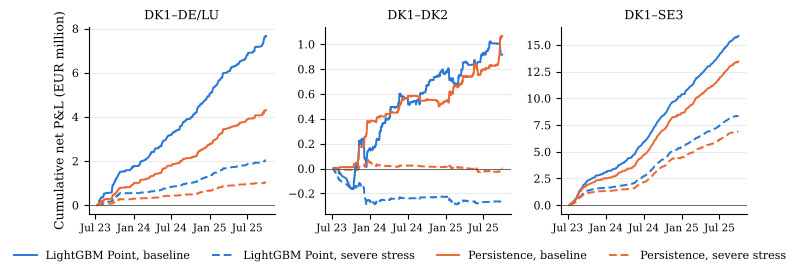

DK1–DE/LU {'LightGBM Point': (7664554, 2027320), 'Persistence': (4300620, 1027918)}
DK1–DK2 {'LightGBM Point': (915658, -267056), 'Persistence': (1064725, -2124)}


DK1–SE3 {'LightGBM Point': (15837002, 8383180), 'Persistence': (13440842, 6919165)}


In [1]:
"""Cumulative net P&L of LightGBM Point and Persistence, baseline and severe stress, one panel per border."""
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SRC = Path("./data_arima_only_4")
OUT = Path("./data_arima_only_figure"); OUT.mkdir(exist_ok=True)
BORDERS = [("DK1_DE_LU", "DK1–DE/LU"), ("DK1_DK2", "DK1–DK2"), ("DK1_SE3", "DK1–SE3")]
MODELS = [("lightgbm_point", "LightGBM Point", "#2a78d6"), ("persistence", "Persistence", "#eb6834")]

def load(path):
    d = pd.read_csv(path, index_col=0)
    d.index = pd.to_datetime(d.index, utc=True)
    return d

plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.7), sharex=True)
for ax, (b, title) in zip(axes, BORDERS):
    base = load(SRC / f"phase5_pnl_curves_{b}.csv")
    sev = load(SRC / f"phase5_execution_stress_pnl_severe_stress_{b}.csv")
    for key, name, col in MODELS:
        ax.plot(base.index, base[f"{key}_fold_tuned"] / 1e6, color=col, lw=1.4, label=f"{name}, baseline")
        ax.plot(sev.index, sev[f"{key}_stress"] / 1e6, color=col, lw=1.4, ls=(0, (4, 2)), label=f"{name}, severe stress")
    ax.axhline(0, color="#52514e", lw=0.6)
    ax.set_title(title, fontsize=9)
    ax.grid(axis="y", color="#e3e2de", lw=0.5)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.tick_params(axis="x", labelsize=7.5)
    ax.tick_params(axis="y", labelsize=8)
axes[0].set_ylabel("Cumulative net P&L (EUR million)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(OUT / "cumulative_pnl_baseline_vs_severe.pdf", bbox_inches="tight")
fig.savefig(OUT / "cumulative_pnl_baseline_vs_severe.png", dpi=300, bbox_inches="tight")
plt.show()
for b, title in BORDERS:
    base = load(SRC / f"phase5_pnl_curves_{b}.csv"); sev = load(SRC / f"phase5_execution_stress_pnl_severe_stress_{b}.csv")
    print(title, {name: (round(base[f"{k}_fold_tuned"].iloc[-1]), round(sev[f"{k}_stress"].iloc[-1])) for k, name, _ in MODELS})


# SHAP

SHAP values show which features drive the final LightGBM predictions. They are descriptive and not causal evidence.

In [9]:
"""SHAP summary plots for the final LightGBM models."""
import shap
import matplotlib.pyplot as plt
import lightgbm as lgb
import pandas as pd
from pathlib import Path

ZONES = {"DK1": "DK_1", "DE_LU": "DE_LU", "DK2": "DK_2", "SE3": "SE_3"}
BORDERS = [("DK1", "DE_LU"), ("DK1", "DK2"), ("DK1", "SE3")]


def get_feature_columns(df: pd.DataFrame) -> list[str]:
    exclude = {f"spread_{a}_{b}" for a, b in BORDERS} | {f"price_{code}" for code in ZONES.values()}
    return [c for c in df.columns if c not in exclude]


def add_interaction_terms(df, base_features, zone_a, zone_b):
    df = df.copy()
    new_cols = []
    code_a, code_b = ZONES[zone_a], ZONES[zone_b]
    wind_diff_col = f"delta_wind_{zone_a}_{zone_b}"
    ntc_col = f"ntc_{code_a}_to_{code_b}"
    resdem_a_col = f"residual_demand_{zone_a}"
    resdem_b_col = f"residual_demand_{zone_b}"
    if ntc_col in df.columns:
        if wind_diff_col in df.columns:
            df["interact_wind_ntc"] = df[wind_diff_col] * df[ntc_col]
            new_cols.append("interact_wind_ntc")
        if resdem_a_col in df.columns and resdem_b_col in df.columns:
            df["residual_demand_diff"] = df[resdem_a_col] - df[resdem_b_col]
            df["interact_resdemand_ntc"] = df["residual_demand_diff"] * df[ntc_col]
            new_cols.extend(["residual_demand_diff", "interact_resdemand_ntc"])
    return df, base_features + new_cols


def run_shap_analysis():
    data_path = Path("./data/model_ready_dataset.parquet")
    df_full = pd.read_parquet(data_path)
    base_features = get_feature_columns(df_full)
    for zone_a, zone_b in BORDERS:
        print(f"\nAnalyzing {zone_a}-{zone_b}...")
        df_border, feature_cols = add_interaction_terms(df_full, base_features, zone_a, zone_b)
        X = df_border[feature_cols].tail(max(1, int(len(df_border) * 0.20)))
        model_path = Path(f"./models/lightgbm_point_final_{zone_a}_{zone_b}.txt")
        if not model_path.exists():
            print(f"Model {model_path} missing. Skipping.")
            continue
        model = lgb.Booster(model_file=str(model_path))
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X)
        shap.summary_plot(shap_values, X, show=False)
        plt.savefig(f"shap_summary_{zone_a}_{zone_b}.png", bbox_inches="tight")
        plt.close()
        print(f"SHAP successfully computed for {len(feature_cols)} features on the latest {len(X)} observations; descriptive only.")

if __name__ == "__main__":
    run_shap_analysis()



Analyzing DK1-DE_LU...
SHAP successfully computed for 57 features on the latest 6394 observations; descriptive only.

Analyzing DK1-DK2...
SHAP successfully computed for 54 features on the latest 6394 observations; descriptive only.

Analyzing DK1-SE3...
SHAP successfully computed for 54 features on the latest 6394 observations; descriptive only.


# Lag-Robustness Check: Day-Ahead Information-Set Sensitivity Test

In [10]:
"""Checks which publication metadata an ENTSO-E API response contains (5 days of DK1 load forecast)."""
import os
from entsoe import EntsoeRawClient
import pandas as pd
import bs4

client = EntsoeRawClient(api_key=os.environ["ENTSOE_API_KEY"])

# Small, cheap query: 5 days of DK1 load forecast.
start = pd.Timestamp("2023-01-01", tz="Europe/Copenhagen")
end = pd.Timestamp("2023-01-06", tz="Europe/Copenhagen")

raw_xml = client.query_load_forecast("DK_1", start=start, end=end)

soup = bs4.BeautifulSoup(raw_xml, "html.parser")

# 1. Is there a document-level createdDateTime, and how many?
created = soup.find_all("createddatetime")
print(f"Number of createdDateTime tags found: {len(created)}")
for c in created:
    print("  ", c.text)

# 2. Is there a document-level revisionNumber, and how many?
revisions = soup.find_all("revisionnumber")
print(f"\nNumber of revisionNumber tags found: {len(revisions)}")
for r in revisions:
    print("  ", r.text)

# 3. How many separate TimeSeries blocks came back for these 5 days?
series = soup.find_all("timeseries")
print(f"\nNumber of <TimeSeries> blocks for a 5-day query: {len(series)}")

# 4. Is createdDateTime inside each TimeSeries block
#    (per day), or only at the document level
#    (one value for the whole query)?
for i, ts in enumerate(series):
    ts_created = ts.find("createddatetime")
    ts_revision = ts.find("revisionnumber")
    period_start = ts.find("start")
    print(f"  TimeSeries {i}: period_start={period_start.text if period_start else None}, "
          f"own createdDateTime={ts_created.text if ts_created else 'NONE (inherits document-level only)'}, "
          f"own revisionNumber={ts_revision.text if ts_revision else 'NONE'}")

Number of createdDateTime tags found: 1
   2026-09-04T20:42:16Z

Number of revisionNumber tags found: 1
   1

Number of <TimeSeries> blocks for a 5-day query: 1
  TimeSeries 0: period_start=2022-12-31T23:00Z, own createdDateTime=NONE (inherits document-level only), own revisionNumber=NONE


The query above shows that ENTSO-E's `createdDateTime` is the time the API response was generated, not the time the forecast was published. It is therefore not possible to verify from the data that the load, wind/solar and NTC forecasts were available at the day-ahead decision time.

The next cell tests how much this matters. Elastic Net and LightGBM Point are re-estimated at all three borders with every forecast-derived feature shifted a further 24 hours back. Persistence and Seasonal Naive only use lags of the target and are unaffected, and the LSTM is left out for runtime. If the main results relied on information that was not available day-ahead, this extra lag should make them clearly worse.

In [11]:
"""Lag-robustness check: Elastic Net and LightGBM Point re-estimated with all forecast-derived features shifted a further 24 hours back."""

import logging
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

try:
    import lightgbm as lgb
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False

try:
    from IPython.display import display
    HAS_IPYTHON = True
except ImportError:
    HAS_IPYTHON = False

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)

DATA_DIR = Path("./data")
INPUT_PATH = DATA_DIR / "model_ready_dataset.parquet"

ZONES = {"DK1": "DK_1", "DE_LU": "DE_LU", "DK2": "DK_2", "SE3": "SE_3"}
BORDERS = [("DK1", "DE_LU"), ("DK1", "DK2"), ("DK1", "SE3")]
TARGET_COLS = [f"spread_{a}_{b}" for a, b in BORDERS]

N_FOLDS = 5
MIN_TRAIN_FRAC = 0.4
EMBARGO_HOURS = 168
EN_CV_SPLITS = 5
SEED = 42

EXTRA_LAG_HOURS = 24  # the additional, deliberately conservative buffer


def style_table(df, caption=None, decimals=3):
    fmt = {c: f"{{:.{decimals}f}}" for c in df.columns if pd.api.types.is_float_dtype(df[c])}
    styler = df.style.format(fmt, na_rep="-").hide(axis="index")
    if caption:
        styler = styler.set_caption(caption)
    if HAS_IPYTHON:
        display(styler)
    else:
        print(f"\n{caption or ''}")
        print(df.to_string(index=False))
    return styler


def get_feature_columns(df):
    exclude = set(TARGET_COLS) | {f"price_{code}" for code in ZONES.values()}
    return [c for c in df.columns if c not in exclude]


def identify_forecast_dependent_columns(feature_cols):
    """Columns derived from ENTSO-E day-ahead forecast products (load, wind, solar, NTC and their interactions)."""
    prefixes = ("load_forecast_", "wind_total_", "delta_wind_",
               "residual_demand_", "ntc_", "interact_")
    return [c for c in feature_cols if c.startswith(prefixes)]


def apply_extra_lag(df, cols, extra_hours=EXTRA_LAG_HOURS):
    """Shift the given columns a further `extra_hours` back."""
    df = df.copy()
    for c in cols:
        df[c] = df[c].shift(extra_hours)
    return df


def add_interaction_terms(df, base_features, zone_a, zone_b):
    df = df.copy()
    new_cols = []
    code_a, code_b = ZONES[zone_a], ZONES[zone_b]
    wind_diff_col = f"delta_wind_{zone_a}_{zone_b}"
    ntc_col = f"ntc_{code_a}_to_{code_b}"
    resdem_a_col = f"residual_demand_{zone_a}"
    resdem_b_col = f"residual_demand_{zone_b}"
    if ntc_col in df.columns:
        if wind_diff_col in df.columns:
            df["interact_wind_ntc"] = df[wind_diff_col] * df[ntc_col]
            new_cols.append("interact_wind_ntc")
        if resdem_a_col in df.columns and resdem_b_col in df.columns:
            df["residual_demand_diff"] = df[resdem_a_col] - df[resdem_b_col]
            df["interact_resdemand_ntc"] = df["residual_demand_diff"] * df[ntc_col]
            new_cols.extend(["residual_demand_diff", "interact_resdemand_ntc"])
    return df, base_features + new_cols


def make_walk_forward_folds(n_rows, n_folds=N_FOLDS, min_train_frac=MIN_TRAIN_FRAC, embargo_hours=EMBARGO_HOURS):
    min_train_size = int(n_rows * min_train_frac)
    remaining = n_rows - min_train_size
    test_size = remaining // n_folds
    folds = []
    train_end = min_train_size
    for _ in range(n_folds):
        test_start = train_end
        test_end = min(test_start + test_size, n_rows)
        if test_start >= n_rows:
            break
        embargoed_train_end = max(0, train_end - embargo_hours)
        folds.append((slice(0, embargoed_train_end), slice(test_start, test_end)))
        train_end = test_end
    return folds


def directional_accuracy(y_true, y_pred):
    return float(np.mean(np.sign(y_true) == np.sign(y_pred)))


def directional_accuracy_threshold(y_true, y_pred, threshold=1.0):
    mask = np.abs(y_true) > threshold
    if not mask.any():
        return float("nan")
    return float(np.mean(np.sign(y_true[mask]) == np.sign(y_pred[mask])))


def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "directional_accuracy": directional_accuracy(y_true, y_pred),
        "directional_accuracy_gt_1": directional_accuracy_threshold(y_true, y_pred),
    }


def _split_for_validation(X_train, y_train, y_val_split=0.15):
    n_val = max(int(len(X_train) * y_val_split), EMBARGO_HOURS + 1)
    if len(X_train) <= n_val + EMBARGO_HOURS:
        raise ValueError("Training window too short for validation plus embargo.")
    val_start = len(X_train) - n_val
    fit_end = val_start - EMBARGO_HOURS
    return X_train.iloc[:fit_end], X_train.iloc[val_start:], y_train.iloc[:fit_end], y_train.iloc[val_start:]


def fit_elastic_net(X_train, y_train, X_test):
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    model = ElasticNetCV(
        l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0], alphas=100,
        cv=TimeSeriesSplit(n_splits=EN_CV_SPLITS, gap=EMBARGO_HOURS),
        max_iter=20000, tol=1e-5, n_jobs=-1,
    )
    model.fit(X_train_s, y_train)
    return model.predict(X_test_s)


def fit_lightgbm_point(X_train, y_train, X_test, y_val_split=0.15):
    X_fit, X_val, y_fit, y_val = _split_for_validation(X_train, y_train, y_val_split)
    train_set = lgb.Dataset(X_fit, label=y_fit)
    val_set = lgb.Dataset(X_val, label=y_val, reference=train_set)
    params = {
        "objective": "regression", "metric": "rmse", "learning_rate": 0.05, "num_leaves": 31,
        "min_data_in_leaf": 20, "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 5,
        "seed": SEED, "feature_fraction_seed": SEED, "bagging_seed": SEED, "data_random_seed": SEED,
        "deterministic": True, "force_col_wise": True, "verbose": -1,
    }
    model = lgb.train(params, train_set, valid_sets=[val_set], num_boost_round=1000,
                      callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])
    return model.predict(X_test, num_iteration=model.best_iteration)


def run_walk_forward_minimal(df, feature_cols, target_col, label):
    """Walk-forward evaluation of Elastic Net and LightGBM Point only."""
    folds = make_walk_forward_folds(len(df))
    rows = []
    for fold_i, (train_idx, test_idx) in enumerate(folds):
        train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
        X_train, y_train = train_df[feature_cols], train_df[target_col]
        X_test, y_test = test_df[feature_cols], test_df[target_col]

        en_preds = fit_elastic_net(X_train, y_train, X_test)
        rows.append({"fold": fold_i, "model": "elastic_net", "scenario": label,
                     **evaluate(y_test.values, en_preds)})

        if HAS_LIGHTGBM:
            lgb_preds = fit_lightgbm_point(X_train, y_train, X_test)
            rows.append({"fold": fold_i, "model": "lightgbm_point", "scenario": label,
                         **evaluate(y_test.values, lgb_preds)})
    return pd.DataFrame(rows)


if __name__ == "__main__":
    if not INPUT_PATH.exists():
        raise FileNotFoundError(f"{INPUT_PATH} not found — run Phase 3 first.")
    full_df = pd.read_parquet(INPUT_PATH)

    all_results = []
    for zone_a, zone_b in BORDERS:
        target_col = f"spread_{zone_a}_{zone_b}"
        log.info(f"\n{'='*70}\nBorder {zone_a}-{zone_b}: lag-robustness check\n{'='*70}")

        base_features = get_feature_columns(full_df)
        df_baseline, feature_cols = add_interaction_terms(full_df, base_features, zone_a, zone_b)
        df_baseline = df_baseline.dropna(subset=feature_cols + [target_col])

        forecast_cols = identify_forecast_dependent_columns(feature_cols)
        log.info(f"[{target_col}] {len(forecast_cols)} forecast-dependent columns will get "
                 f"an extra {EXTRA_LAG_HOURS}h lag: {forecast_cols}")

        df_stressed = apply_extra_lag(df_baseline, forecast_cols, EXTRA_LAG_HOURS)
        df_stressed = df_stressed.dropna(subset=feature_cols + [target_col])

        log.info(f"[{target_col}] baseline rows={len(df_baseline)}, "
                 f"stressed rows={len(df_stressed)} (fewer due to extra lag)")

        res_baseline = run_walk_forward_minimal(df_baseline, feature_cols, target_col, "baseline")
        res_stressed = run_walk_forward_minimal(df_stressed, feature_cols, target_col,
                                                f"extra_{EXTRA_LAG_HOURS}h_lag")

        combined = pd.concat([res_baseline, res_stressed], ignore_index=True)
        combined["border"] = f"{zone_a}_{zone_b}"
        all_results.append(combined)

        summary = combined.groupby(["scenario", "model"])[["rmse", "mae", "directional_accuracy",
                                                            "directional_accuracy_gt_1"]].mean().reset_index()
        style_table(summary, caption=f"Lag-robustness check — {zone_a}-{zone_b} "
                                     f"(baseline vs. extra {EXTRA_LAG_HOURS}h lag)")

    all_results_df = pd.concat(all_results, ignore_index=True)
    all_results_df.to_csv(DATA_DIR / "lag_robustness_check_all_borders.csv", index=False)
    log.info(f"Saved -> {DATA_DIR / 'lag_robustness_check_all_borders.csv'}")

2026-09-04 22:42:16,580 | INFO | 
Border DK1-DE_LU: lag-robustness check
2026-09-04 22:42:16,586 | INFO | [spread_DK1_DE_LU] 20 forecast-dependent columns will get an extra 24h lag: ['load_forecast_DE_LU', 'load_forecast_DK_1', 'load_forecast_DK_2', 'load_forecast_SE_3', 'ntc_DK_1_to_DE_LU', 'ntc_DE_LU_to_DK_1', 'wind_total_DE_LU', 'wind_total_DK1', 'wind_total_DK2', 'wind_total_SE3', 'delta_wind_DK1_DE_LU', 'delta_wind_DK1_DK2', 'delta_wind_DK1_SE3', 'residual_demand_DE_LU', 'residual_demand_DK1', 'residual_demand_DK2', 'residual_demand_SE3', 'interact_wind_ntc', 'residual_demand_diff', 'interact_resdemand_ntc']
2026-09-04 22:42:16,598 | INFO | [spread_DK1_DE_LU] baseline rows=31972, stressed rows=31948 (fewer due to extra lag)
/opt/anaconda3/envs/my_env_311/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:701: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increas

scenario,model,rmse,mae,directional_accuracy,directional_accuracy_gt_1
baseline,elastic_net,18.545,11.705,0.391,0.924
baseline,lightgbm_point,17.598,9.169,0.401,0.941
extra_24h_lag,elastic_net,18.538,11.919,0.388,0.913
extra_24h_lag,lightgbm_point,17.321,10.007,0.392,0.925


2026-09-04 22:42:29,334 | INFO | 
Border DK1-DK2: lag-robustness check
2026-09-04 22:42:29,337 | INFO | [spread_DK1_DK2] 17 forecast-dependent columns will get an extra 24h lag: ['load_forecast_DE_LU', 'load_forecast_DK_1', 'load_forecast_DK_2', 'load_forecast_SE_3', 'ntc_DK_1_to_DE_LU', 'ntc_DE_LU_to_DK_1', 'wind_total_DE_LU', 'wind_total_DK1', 'wind_total_DK2', 'wind_total_SE3', 'delta_wind_DK1_DE_LU', 'delta_wind_DK1_DK2', 'delta_wind_DK1_SE3', 'residual_demand_DE_LU', 'residual_demand_DK1', 'residual_demand_DK2', 'residual_demand_SE3']
2026-09-04 22:42:29,345 | INFO | [spread_DK1_DK2] baseline rows=31972, stressed rows=31948 (fewer due to extra lag)
/opt/anaconda3/envs/my_env_311/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:701: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.040e+02, tolerance: 1.609e+02
  model = cd

scenario,model,rmse,mae,directional_accuracy,directional_accuracy_gt_1
baseline,elastic_net,15.022,8.615,0.248,0.570
baseline,lightgbm_point,15.575,8.855,0.223,0.492
extra_24h_lag,elastic_net,15.003,8.432,0.252,0.578
extra_24h_lag,lightgbm_point,15.606,8.618,0.255,0.566


2026-09-04 22:42:36,862 | INFO | 
Border DK1-SE3: lag-robustness check
2026-09-04 22:42:36,867 | INFO | [spread_DK1_SE3] 17 forecast-dependent columns will get an extra 24h lag: ['load_forecast_DE_LU', 'load_forecast_DK_1', 'load_forecast_DK_2', 'load_forecast_SE_3', 'ntc_DK_1_to_DE_LU', 'ntc_DE_LU_to_DK_1', 'wind_total_DE_LU', 'wind_total_DK1', 'wind_total_DK2', 'wind_total_SE3', 'delta_wind_DK1_DE_LU', 'delta_wind_DK1_DK2', 'delta_wind_DK1_SE3', 'residual_demand_DE_LU', 'residual_demand_DK1', 'residual_demand_DK2', 'residual_demand_SE3']
2026-09-04 22:42:36,876 | INFO | [spread_DK1_SE3] baseline rows=31972, stressed rows=31948 (fewer due to extra lag)
/opt/anaconda3/envs/my_env_311/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:701: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.209e+03, tolerance: 8.893e+02
  model = cd

scenario,model,rmse,mae,directional_accuracy,directional_accuracy_gt_1
baseline,elastic_net,31.715,23.673,0.743,0.850
baseline,lightgbm_point,29.545,20.711,0.794,0.911
extra_24h_lag,elastic_net,30.961,22.786,0.748,0.855
extra_24h_lag,lightgbm_point,28.207,20.252,0.787,0.901


2026-09-04 22:42:48,559 | INFO | Saved -> data/lag_robustness_check_all_borders.csv
